# Telco Customer Churn — EDA & Predictive Modeling

**Dataset:** IBM Telco Customer Churn (7,043 customers).  
**Target:** `Churn`

Flow:
1. Setup & Imports
2. Load & Clean Data
3. Feature Engineering
4. Train/Test Split
5. Preprocessing & Helpers
6. Imbalance Strategy Experiment (No Balance · Class Weight · SMOTE) on all models
7. Baseline Model Comparison (best strategy per model)
8. Hyperparameter Tuning
9. Model Comparison
10. Threshold Optimization
11. Cost-Sensitive Decision
12. Probability Calibration
13. Cross-Validation Stability
14. Final Model Selection
15. Final Evaluation
16. Optional Stacking
17. SHAP Explainability
18. Model Saving
19. Executive Summary


## 1. Setup & Imports

In [1]:
import warnings, time, subprocess, sys
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    brier_score_loss, classification_report, roc_curve, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, StackingClassifier

from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
N_JOBS = -1

# ── Plot style ────────────────────────────────────────────────────────────────
BLUE, RED   = "#4C8CBF", "#E05C5C"
GREEN, ORANGE, PURPLE = "#2A9D8F", "#F4A261", "#6D597A"
BG = "#F8F9FA"
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": BG, "axes.facecolor": BG,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

print("✅ Imports complete.")


✅ Imports complete.


## 2. Load & Clean Data

In [2]:
LOCAL_PATHS = [
    Path("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"),
    Path("telco.csv"),
    Path("WA_Fn-UseC_-Telco-Customer-Churn.csv"),
]
FALLBACK_URL = (
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)

df_raw = None
for p in LOCAL_PATHS:
    if p.exists():
        df_raw = pd.read_csv(p)
        print(f"✅ Loaded from local path: {p}")
        break

if df_raw is None:
    df_raw = pd.read_csv(FALLBACK_URL)
    print("✅ Loaded from GitHub mirror.")

print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
df_raw.head(3)


✅ Loaded from local path: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: 7,043 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes


In [3]:
df = df_raw.copy()

# TotalCharges has blank strings for brand-new customers (tenure=0) → coerce to 0
blank_total_charges = (df["TotalCharges"].astype(str).str.strip() == "").sum()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# Binary-encode target
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Tenure buckets
df["TenureGroup"] = pd.cut(
    df["tenure"], bins=[-1, 12, 24, 48, 72],
    labels=["0–12 mo", "13–24 mo", "25–48 mo", "49+ mo"],
)

print("✅ Cleaning done.")
print(f"   'TotalCharges' blanks converted to 0: {blank_total_charges}")
print(f"   Missing values remaining: {df.isnull().sum().sum()}")
print(f"   Churn rate: {df['Churn'].mean():.2%}")


✅ Cleaning done.
   'TotalCharges' blanks converted to 0: 11
   Missing values remaining: 0
   Churn rate: 26.54%


## 3. Feature Engineering

In [4]:
df_ml = df.copy()

df_ml["AvgMonthlySpend"]   = df_ml["TotalCharges"] / (df_ml["tenure"] + 1)
df_ml["IsNewCustomer"]     = (df_ml["tenure"] <= 6).astype(int)
df_ml["HighMonthlyCharge"] = (df_ml["MonthlyCharges"] > df_ml["MonthlyCharges"].median()).astype(int)

service_cols = [
    "PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
]
df_ml["ServicesCount"] = df_ml[service_cols].eq("Yes").sum(axis=1)
df_ml["AutoPayment"]   = df_ml["PaymentMethod"].str.contains("automatic").astype(int)

print(f"✅ Feature engineering done. Shape: {df_ml.shape}")
df_ml.head(3)


✅ Feature engineering done. Shape: (7043, 27)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,AvgMonthlySpend,IsNewCustomer,HighMonthlyCharge,ServicesCount,AutoPayment
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.850,0,0–12 mo,14.925,1,0,1,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.500,0,25–48 mo,53.986,0,0,3,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.150,1,0–12 mo,36.050,1,0,3,0


## 4. Train/Test Split

Test set is held back before any preprocessing, resampling, threshold tuning, or model selection.
All modeling decisions use only train/val data; test labels are touched only in Section 15.

In [5]:
X = df_ml.drop(columns=["customerID", "Churn"])
y = df_ml["Churn"].astype(int)

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_features   = X.select_dtypes(exclude=["object", "category"]).columns.tolist()

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y_train_val,
)

print(f"Train:      {X_train.shape} | Churn rate: {y_train.mean():.2%}")
print(f"Validation: {X_val.shape}  | Churn rate: {y_val.mean():.2%}")
print(f"Test:       {X_test.shape}  | Churn rate: {y_test.mean():.2%}")
print(f"Numeric features: {len(numerical_features)} | Categorical features: {len(categorical_features)}")


Train:      (4507, 25) | Churn rate: 26.54%
Validation: (1127, 25)  | Churn rate: 26.53%
Test:       (1409, 25)  | Churn rate: 26.54%
Numeric features: 9 | Categorical features: 16


## 5. Preprocessing & Helpers

Every model uses the same leakage-safe preprocessing: median imputation + scaling for numeric,
most-frequent imputation + one-hot encoding for categoricals. Fitted only on the training split.

In [6]:
# ── Preprocessor factory ──────────────────────────────────────────────────────
def build_preprocessor(X_reference=None):
    """Fresh ColumnTransformer — never reuse a fitted one across experiments."""
    num_cols = (X_reference.select_dtypes(exclude=["object", "category"]).columns.tolist()
                if X_reference is not None else numerical_features)
    cat_cols = (X_reference.select_dtypes(include=["object", "category"]).columns.tolist()
                if X_reference is not None else categorical_features)
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),
    ])


# ── Imbalance helpers ─────────────────────────────────────────────────────────
def scale_pos_weight_from_y(y_values, strategy):
    """XGBoost scale_pos_weight: only meaningful when strategy == 'class_weight'."""
    if strategy != "class_weight":
        return 1.0
    positives = int((y_values == 1).sum())
    negatives = int((y_values == 0).sum())
    return negatives / max(positives, 1)


def class_weight_value(strategy):
    return "balanced" if strategy == "class_weight" else None


# ── Pipeline factory ──────────────────────────────────────────────────────────
def make_model_pipeline(model, balance_strategy="none", X_reference=None):
    """
    balance_strategy:
      'none'         – no resampling, no class_weight in preprocessor
      'smote'        – SMOTE oversampling inside the pipeline (ImbPipeline)
      'class_weight' – handled inside the model itself; pipeline is plain sklearn
    """
    steps = [("preprocessor", build_preprocessor(X_reference))]
    if balance_strategy == "smote":
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
        return ImbPipeline(steps + [("model", model)])
    return Pipeline(steps + [("model", model)])


# ── Metric helpers ────────────────────────────────────────────────────────────
def metric_dict(y_true, y_prob, threshold=0.50):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred, zero_division=0),
        "F1":        f1_score(y_true, y_pred, zero_division=0),
        "ROC AUC":   roc_auc_score(y_true, y_prob),
    }


def threshold_table(y_true, y_prob, thresholds=None):
    thresholds = thresholds or np.arange(0.10, 0.91, 0.01)
    rows = [{"Threshold": round(float(t), 2), **metric_dict(y_true, y_prob, threshold=t)}
            for t in thresholds]
    return pd.DataFrame(rows)


def cost_table(y_true, y_prob, fp_cost=1, fn_cost=5, thresholds=None):
    thresholds = thresholds or np.arange(0.10, 0.91, 0.01)
    rows = []
    for t in thresholds:
        pred = (y_prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows.append({
            "Threshold": round(float(t), 2),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Total Expected Cost": fp * fp_cost + fn * fn_cost,
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall":    recall_score(y_true, pred, zero_division=0),
            "F1":        f1_score(y_true, pred, zero_division=0),
        })
    return pd.DataFrame(rows)


# ── XGBoost factory ───────────────────────────────────────────────────────────
def build_xgb_classifier(**overrides):
    params = {
        "objective": "binary:logistic", "eval_metric": "logloss",
        "n_estimators": 300, "learning_rate": 0.05, "max_depth": 3,
        "subsample": 0.85, "colsample_bytree": 0.85, "min_child_weight": 1,
        "reg_alpha": 0.0, "reg_lambda": 1.0,
        "random_state": RANDOM_STATE, "n_jobs": N_JOBS, "verbosity": 0,
    }
    params.update(overrides)
    return XGBClassifier(**params)


# ── Model registry ────────────────────────────────────────────────────────────
model_registry = {}

def register_model(name, learning_type, family, variant, estimator,
                   val_prob, train_time, inference_time, balance_strategy):
    metrics = metric_dict(y_val, val_prob, threshold=0.50)
    row = {
        "Model": name,
        "Learning Type": learning_type,
        "Variant": variant,
        "Applied Balance": balance_strategy,
        **metrics,
        "Training Time (s)": round(float(train_time), 3),
        "Inference Time (ms/row)": round(float(inference_time) * 1000 / len(X_val), 4),
    }
    model_registry[name] = {
        "learning_type": learning_type, "family": family, "variant": variant,
        "estimator": estimator, "val_prob": np.asarray(val_prob),
        "train_time": train_time, "inference_time": inference_time,
        "balance_strategy": balance_strategy, "metrics": row,
    }
    return row

print("✅ Preprocessing and evaluation helpers ready.")


✅ Preprocessing and evaluation helpers ready.


## 6. Imbalance Strategy Experiment

Compares **No Balancing**, **Class Weight**, and **SMOTE** across **all 5 model families**.
This gives a complete picture — best strategy for LR is not necessarily best for RF.

Decision rule: the strategy with the highest **mean F1** across all models wins overall;
individual model sections still use whatever works best for them.


In [7]:
# ── Model specs for the experiment ────────────────────────────────────────────
EXPERIMENT_MODELS = {
    "Logistic Regression": lambda cw, spw: LogisticRegression(
        max_iter=2000, class_weight=cw, random_state=RANDOM_STATE),
    "KNN":  lambda cw, spw: KNeighborsClassifier(n_neighbors=25, weights="distance"),
    "SVM":  lambda cw, spw: SVC(kernel="rbf", C=1.0, gamma="scale",
                                class_weight=cw, probability=True, random_state=RANDOM_STATE),
    "Random Forest": lambda cw, spw: RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=2,
        class_weight=cw, random_state=RANDOM_STATE, n_jobs=N_JOBS),
    "XGBoost": lambda cw, spw: build_xgb_classifier(scale_pos_weight=spw),
}

STRATEGIES = {
    # FIX: 'Class Weight' was incorrectly mapped to strategy='none' before
    "No Balancing": "none",
    "Class Weight":  "class_weight",   # ← was 'none' — BUG FIXED
    "SMOTE":         "smote",
}

imbalance_rows = []
for strategy_label, strategy_key in STRATEGIES.items():
    cw  = class_weight_value(strategy_key)
    spw = scale_pos_weight_from_y(y_train, strategy_key)
    for model_name, model_fn in EXPERIMENT_MODELS.items():
        model = model_fn(cw, spw)
        pipe  = make_model_pipeline(model, balance_strategy=strategy_key)
        t0    = time.time()
        pipe.fit(X_train, y_train)
        t_train = time.time() - t0
        val_prob = pipe.predict_proba(X_val)[:, 1]
        metrics  = metric_dict(y_val, val_prob)
        imbalance_rows.append({
            "Model": model_name,
            "Strategy": strategy_label,
            **metrics,
            "Training Time (s)": round(t_train, 2),
        })
        print(f"  {model_name:20s} | {strategy_label:14s} | F1={metrics['F1']:.3f} | AUC={metrics['ROC AUC']:.3f}")

imbalance_exp_df = pd.DataFrame(imbalance_rows)
print("\n✅ Imbalance experiment done.")


  Logistic Regression  | No Balancing   | F1=0.612 | AUC=0.852
  KNN                  | No Balancing   | F1=0.581 | AUC=0.815
  SVM                  | No Balancing   | F1=0.537 | AUC=0.818
  Random Forest        | No Balancing   | F1=0.573 | AUC=0.848
  XGBoost              | No Balancing   | F1=0.600 | AUC=0.852
  Logistic Regression  | Class Weight   | F1=0.633 | AUC=0.852
  KNN                  | Class Weight   | F1=0.581 | AUC=0.815
  SVM                  | Class Weight   | F1=0.631 | AUC=0.835
  Random Forest        | Class Weight   | F1=0.633 | AUC=0.846
  XGBoost              | Class Weight   | F1=0.633 | AUC=0.848
  Logistic Regression  | SMOTE          | F1=0.634 | AUC=0.851
  KNN                  | SMOTE          | F1=0.587 | AUC=0.804
  SVM                  | SMOTE          | F1=0.634 | AUC=0.836
  Random Forest        | SMOTE          | F1=0.647 | AUC=0.844
  XGBoost              | SMOTE          | F1=0.641 | AUC=0.850

✅ Imbalance experiment done.


=== F1 Score by Model × Strategy ===


Strategy,Class Weight,No Balancing,SMOTE
Model,,,
KNN,0.581,0.581,0.587
Logistic Regression,0.633,0.612,0.634
Random Forest,0.633,0.573,0.647
SVM,0.631,0.537,0.634
XGBoost,0.633,0.600,0.641



=== ROC AUC by Model × Strategy ===


Strategy,Class Weight,No Balancing,SMOTE
Model,,,
KNN,0.815,0.815,0.804
Logistic Regression,0.852,0.852,0.851
Random Forest,0.846,0.848,0.844
SVM,0.835,0.818,0.836
XGBoost,0.848,0.852,0.850


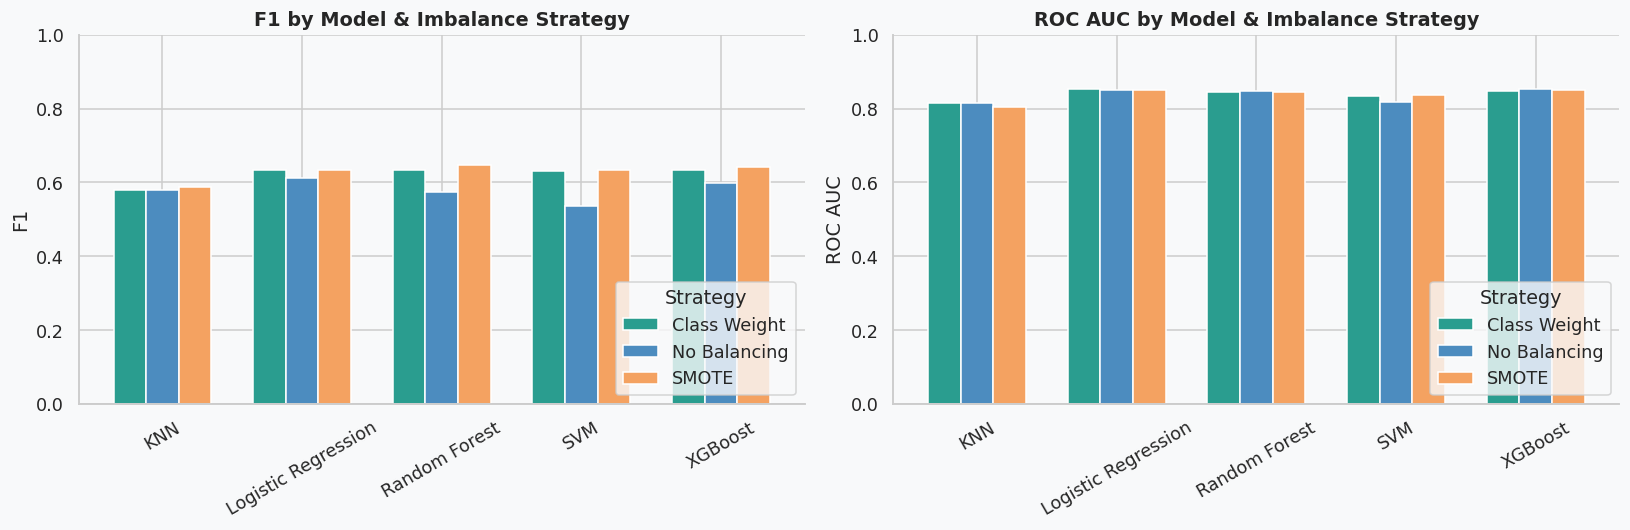


=== Mean F1 across all models by strategy ===


,Mean F1
Strategy,
SMOTE,0.628
Class Weight,0.622
No Balancing,0.581



>>> Selected global imbalance strategy: SMOTE (smote)
    (Used as default for downstream models. Per-model best will override in Section 8.)


In [8]:
# ── Pivot: F1 per Model × Strategy ───────────────────────────────────────────
pivot_f1 = imbalance_exp_df.pivot(index="Model", columns="Strategy", values="F1")
pivot_auc = imbalance_exp_df.pivot(index="Model", columns="Strategy", values="ROC AUC")

print("=== F1 Score by Model × Strategy ===")
display(pivot_f1.round(3))

print("\n=== ROC AUC by Model × Strategy ===")
display(pivot_auc.round(3))

# ── Bar chart comparison ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
strategy_colors = {"No Balancing": BLUE, "Class Weight": GREEN, "SMOTE": ORANGE}

for ax, metric_label in zip(axes, ["F1", "ROC AUC"]):
    pivot = imbalance_exp_df.pivot(index="Model", columns="Strategy", values=metric_label)
    pivot.plot(kind="bar", ax=ax, color=[strategy_colors[c] for c in pivot.columns],
               edgecolor="white", width=0.7)
    ax.set_title(f"{metric_label} by Model & Imbalance Strategy", fontweight="bold")
    ax.set_ylabel(metric_label)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Strategy", loc="lower right")
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

# ── Mean F1 per strategy (aggregate decision) ─────────────────────────────────
mean_f1_by_strategy = (
    imbalance_exp_df.groupby("Strategy")["F1"]
    .mean().sort_values(ascending=False)
)
print("\n=== Mean F1 across all models by strategy ===")
display(mean_f1_by_strategy.to_frame("Mean F1").round(4))

strategy_lookup = {"No Balancing": "none", "Class Weight": "class_weight", "SMOTE": "smote"}
BEST_IMBALANCE_LABEL = mean_f1_by_strategy.index[0]
BEST_IMBALANCE_STRATEGY = strategy_lookup[BEST_IMBALANCE_LABEL]

print(f"\n>>> Selected global imbalance strategy: {BEST_IMBALANCE_LABEL} ({BEST_IMBALANCE_STRATEGY})")
print("    (Used as default for downstream models. Per-model best will override in Section 8.)")


## 7. Baseline Model Comparison

Each model is trained with the best imbalance strategy selected in Section 6.
Covers linear, distance-based, kernel, bagging, and boosting families.

In [9]:
base_balance = "smote" if BEST_IMBALANCE_STRATEGY == "smote" else "none"
cw  = class_weight_value(BEST_IMBALANCE_STRATEGY)
spw = scale_pos_weight_from_y(y_train, BEST_IMBALANCE_STRATEGY)

baseline_specs = [
    ("Logistic Regression", "Linear model", "Linear",
     LogisticRegression(max_iter=2000, class_weight=cw, random_state=RANDOM_STATE), base_balance),
    ("KNN", "Distance-based", "Distance",
     KNeighborsClassifier(n_neighbors=25, weights="distance"), base_balance),
    ("SVM", "Kernel-based", "Kernel",
     SVC(kernel="rbf", C=1.0, gamma="scale", class_weight=cw,
         probability=True, random_state=RANDOM_STATE), base_balance),
    ("Random Forest", "Bagging ensemble", "Bagging",
     RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=2,
                            class_weight=cw, random_state=RANDOM_STATE, n_jobs=N_JOBS), base_balance),
    ("XGBoost", "Gradient boosting", "Boosting",
     build_xgb_classifier(scale_pos_weight=spw), base_balance),
]

baseline_rows = []
for name, lt, fam, model, bal in baseline_specs:
    pipe = make_model_pipeline(model, balance_strategy=bal)
    t0   = time.time()
    pipe.fit(X_train, y_train)
    t_train = time.time() - t0
    t1 = time.time()
    val_prob = pipe.predict_proba(X_val)[:, 1]
    t_inf = time.time() - t1
    bal_label = ("SMOTE" if bal == "smote"
                 else "Class Weight" if BEST_IMBALANCE_STRATEGY == "class_weight" and name != "KNN"
                 else "None")
    row = register_model(name=name, learning_type=lt, family=fam, variant="Baseline",
                         estimator=pipe, val_prob=val_prob,
                         train_time=t_train, inference_time=t_inf,
                         balance_strategy=bal_label)
    baseline_rows.append(row)
    print(f"  {name:20s} | F1={row['F1']:.3f} | AUC={row['ROC AUC']:.3f} | {t_train:.1f}s")

baseline_df = (
    pd.DataFrame(baseline_rows)
    .sort_values(["F1", "ROC AUC"], ascending=False)
    .reset_index(drop=True)
)
display(baseline_df)


  Logistic Regression  | F1=0.634 | AUC=0.851 | 0.1s
  KNN                  | F1=0.587 | AUC=0.804 | 0.1s
  SVM                  | F1=0.634 | AUC=0.836 | 9.5s
  Random Forest        | F1=0.635 | AUC=0.841 | 1.3s
  XGBoost              | F1=0.641 | AUC=0.850 | 0.5s


,Model,Learning Type,Variant,Applied Balance,Accuracy,Precision,Recall,F1,ROC AUC,Training Time (s),Inference Time (ms/row)
0,XGBoost,Gradient boosting,Baseline,SMOTE,0.812,0.649,0.632,0.641,0.850,0.475,0.013
1,Random Forest,Bagging ensemble,Baseline,SMOTE,0.797,0.607,0.666,0.635,0.841,1.303,0.096
2,Logistic Regression,Linear model,Baseline,SMOTE,0.762,0.536,0.776,0.634,0.851,0.133,0.015
3,SVM,Kernel-based,Baseline,SMOTE,0.776,0.560,0.729,0.634,0.836,9.510,0.292
4,KNN,Distance-based,Baseline,SMOTE,0.702,0.464,0.799,0.587,0.804,0.094,0.044


## 8. Hyperparameter Tuning

SVM, Random Forest, and XGBoost are tuned. LR and KNN remain as baselines.
All tuning is done on the training set with 3-fold CV; validation set is not touched.

In [10]:
def search_and_replace(name, lt, fam, model, param_dist, n_iter,
                      scoring="f1", bal=base_balance):
    pipe = make_model_pipeline(model, balance_strategy=bal)
    search = RandomizedSearchCV(
        estimator=pipe, param_distributions=param_dist, n_iter=n_iter,
        scoring=scoring, cv=3, random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=0,
    )
    t0 = time.time()
    search.fit(X_train, y_train)
    t_train = time.time() - t0
    t1 = time.time()
    val_prob = search.predict_proba(X_val)[:, 1]
    t_inf = time.time() - t1
    bal_label = ("SMOTE" if bal == "smote"
                 else "Class Weight" if BEST_IMBALANCE_STRATEGY == "class_weight"
                 else "None")
    row = register_model(name=name, learning_type=lt, family=fam, variant="Tuned",
                         estimator=search.best_estimator_, val_prob=val_prob,
                         train_time=t_train, inference_time=t_inf,
                         balance_strategy=bal_label)
    return search, row

# ── SVM ───────────────────────────────────────────────────────────────────────
svm_search, svm_row = search_and_replace(
    "SVM", "Kernel-based", "Kernel",
    SVC(kernel="rbf", class_weight=cw, probability=True, random_state=RANDOM_STATE),
    {"model__C": [0.5, 1, 2, 5, 10], "model__gamma": ["scale", 0.01, 0.03, 0.10]},
    n_iter=8, scoring="f1",
)
best_svm_params = {k.replace("model__", ""): v for k, v in svm_search.best_params_.items()}
print(f"SVM best CV F1: {svm_search.best_score_:.4f} | params: {best_svm_params}")

# ── Random Forest ─────────────────────────────────────────────────────────────
rf_search, rf_row = search_and_replace(
    "Random Forest", "Bagging ensemble", "Bagging",
    RandomForestClassifier(class_weight=cw, random_state=RANDOM_STATE, n_jobs=N_JOBS),
    {
        "model__n_estimators":   [250, 350, 500],
        "model__max_depth":      [8, 12, 16, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf":  [1, 2, 4],
        "model__max_features":   ["sqrt", "log2"],
    },
    n_iter=10, scoring="f1",
)
best_rf_params = {k.replace("model__", ""): v for k, v in rf_search.best_params_.items()}
print(f"RF   best CV F1: {rf_search.best_score_:.4f} | params: {best_rf_params}")


SVM best CV F1: 0.6269 | params: {'gamma': 0.01, 'C': 0.5}
RF   best CV F1: 0.6348 | params: {'n_estimators': 250, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 8}


### 8.1 XGBoost — RandomSearch + Early Stopping

In [11]:
# ── XGBoost RandomSearch ──────────────────────────────────────────────────────
xgb_search_base = build_xgb_classifier(
    scale_pos_weight=scale_pos_weight_from_y(y_train, BEST_IMBALANCE_STRATEGY)
)
xgb_search_pipe = make_model_pipeline(xgb_search_base, balance_strategy=base_balance)

xgb_param_dist = {
    "model__n_estimators":      [250, 400, 600],
    "model__max_depth":         [3, 4, 5],
    "model__learning_rate":     [0.025, 0.05, 0.08, 0.10],
    "model__subsample":         [0.75, 0.85, 1.0],
    "model__colsample_bytree":  [0.70, 0.85, 1.0],
    "model__min_child_weight":  [1, 3, 5],
    "model__reg_alpha":         [0, 0.05, 0.10, 0.50],
    "model__reg_lambda":        [0.75, 1.0, 2.0, 4.0],
}
xgb_search = RandomizedSearchCV(
    estimator=xgb_search_pipe, param_distributions=xgb_param_dist,
    n_iter=12, scoring="roc_auc", cv=3,
    random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=0,
)
t0 = time.time()
xgb_search.fit(X_train, y_train)
xgb_search_time = time.time() - t0
best_xgb_params = {k.replace("model__", ""): v for k, v in xgb_search.best_params_.items()}
print(f"XGB  best CV AUC: {xgb_search.best_score_:.4f} | params: {best_xgb_params}")

# ── Early stopping fit ────────────────────────────────────────────────────────
xgb_prep = build_preprocessor()
xgb_prep.fit(X_train)
X_tr_xgb = xgb_prep.transform(X_train)
X_va_xgb = xgb_prep.transform(X_val)

y_tr_xgb = y_train.copy()
if BEST_IMBALANCE_STRATEGY == "smote":
    X_tr_xgb, y_tr_xgb = SMOTE(random_state=RANDOM_STATE).fit_resample(X_tr_xgb, y_tr_xgb)

es_params = {"objective": "binary:logistic", "eval_metric": "logloss",
             "random_state": RANDOM_STATE, "n_jobs": N_JOBS, "verbosity": 0,
             "scale_pos_weight": scale_pos_weight_from_y(y_train, BEST_IMBALANCE_STRATEGY)}
es_params.update(best_xgb_params)
es_params["n_estimators"] = max(int(es_params.get("n_estimators", 400)), 800)

t0 = time.time()
xgb_es = XGBClassifier(**es_params, early_stopping_rounds=25)
xgb_es.fit(X_tr_xgb, y_tr_xgb, eval_set=[(X_va_xgb, y_val)], verbose=False)
xgb_es_time = time.time() - t0

# FIX: use ImbPipeline if SMOTE was applied, else plain Pipeline
# The preprocessor is already fitted, so we wrap it in a pipeline for predict_proba
xgb_es_pipeline = Pipeline([("preprocessor", xgb_prep), ("model", xgb_es)])

t1 = time.time()
xgb_es_val_prob = xgb_es_pipeline.predict_proba(X_val)[:, 1]
xgb_es_inf_time = time.time() - t1

register_model(
    name="XGBoost", learning_type="Gradient boosting", family="Boosting",
    variant="Tuned+ES",
    estimator=xgb_es_pipeline, val_prob=xgb_es_val_prob,
    train_time=xgb_search_time + xgb_es_time, inference_time=xgb_es_inf_time,
    balance_strategy=("SMOTE" if BEST_IMBALANCE_STRATEGY == "smote"
                      else "Class Weight" if BEST_IMBALANCE_STRATEGY == "class_weight"
                      else "None"),
)
print(f"XGBoost ES training time: {xgb_es_time:.1f}s | best iter: {getattr(xgb_es, 'best_iteration', 'N/A')}")


XGB  best CV AUC: 0.8416 | params: {'subsample': 0.85, 'reg_lambda': 2.0, 'reg_alpha': 0, 'n_estimators': 250, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.025, 'colsample_bytree': 0.85}
XGBoost ES training time: 0.9s | best iter: 542


## 9. Model Comparison

Leaderboard with one row per family (the tuned version if available).
F1 and ROC AUC are the primary criteria; accuracy is reported but not used for selection.

,Model,Learning Type,Variant,Applied Balance,Accuracy,Precision,Recall,F1,ROC AUC,Training Time (s),Inference Time (ms/row)
0,XGBoost,Gradient boosting,Tuned+ES,SMOTE,0.809,0.642,0.635,0.639,0.852,18.924,0.014
1,Random Forest,Bagging ensemble,Tuned,SMOTE,0.782,0.570,0.722,0.637,0.847,23.818,0.089
2,SVM,Kernel-based,Tuned,SMOTE,0.762,0.535,0.786,0.637,0.848,60.377,0.311
3,Logistic Regression,Linear model,Baseline,SMOTE,0.762,0.536,0.776,0.634,0.851,0.133,0.015
4,KNN,Distance-based,Baseline,SMOTE,0.702,0.464,0.799,0.587,0.804,0.094,0.044


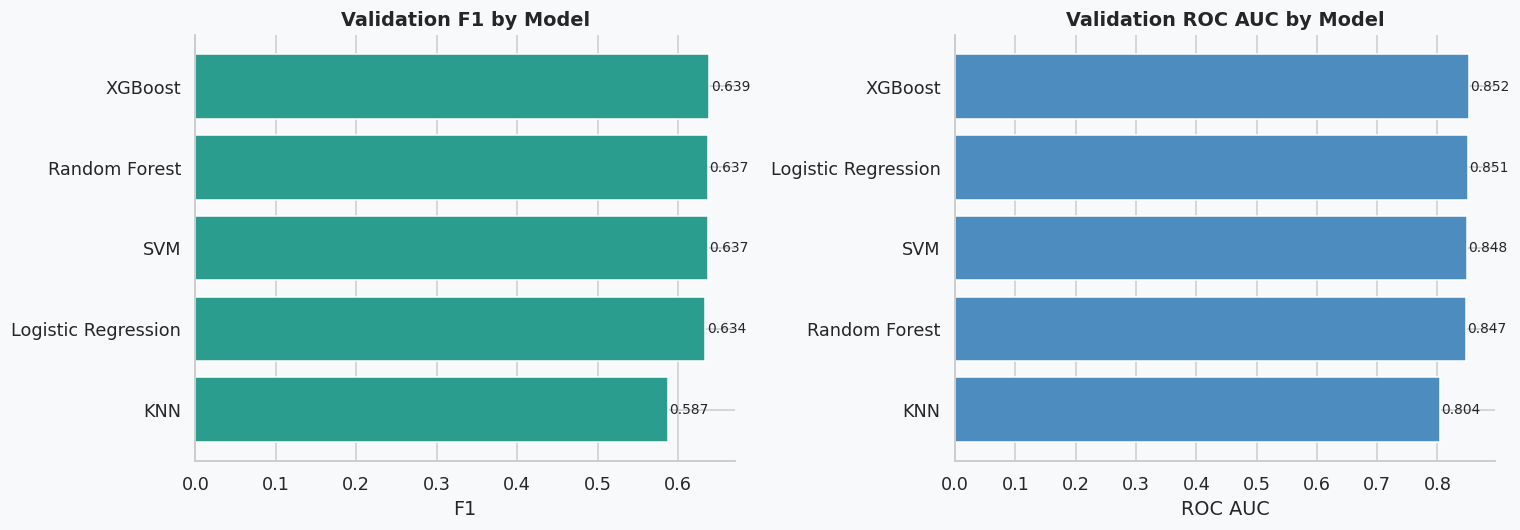

Preliminary best model by F1: XGBoost


In [12]:
model_order = ["Logistic Regression", "KNN", "SVM", "Random Forest", "XGBoost"]
comparison_rows = [model_registry[n]["metrics"] for n in model_order if n in model_registry]

model_comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values(["F1", "ROC AUC", "Recall"], ascending=False)
    .reset_index(drop=True)
)
display(model_comparison_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, color in zip(axes, ["F1", "ROC AUC"], [GREEN, BLUE]):
    plot_df = model_comparison_df.sort_values(metric)
    ax.barh(plot_df["Model"], plot_df[metric], color=color, edgecolor="white")
    ax.set_title(f"Validation {metric} by Model", fontweight="bold")
    ax.set_xlabel(metric)
    for i, v in enumerate(plot_df[metric]):
        ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

preliminary_best_model_name = model_comparison_df.iloc[0]["Model"]
print(f"Preliminary best model by F1: {preliminary_best_model_name}")


def get_candidate_template(name):
    """Return an unfitted sklearn-compatible estimator for CV / calibration."""
    bal   = "smote" if BEST_IMBALANCE_STRATEGY == "smote" else "none"
    cw_l  = class_weight_value(BEST_IMBALANCE_STRATEGY)
    spw_l = scale_pos_weight_from_y(y_train, BEST_IMBALANCE_STRATEGY)
    if name == "Logistic Regression":
        return make_model_pipeline(
            LogisticRegression(max_iter=2000, class_weight=cw_l, random_state=RANDOM_STATE), bal)
    if name == "KNN":
        return make_model_pipeline(KNeighborsClassifier(n_neighbors=25, weights="distance"), bal)
    if name == "SVM":
        p = {"kernel": "rbf", "probability": True, "class_weight": cw_l, "random_state": RANDOM_STATE}
        p.update(best_svm_params)
        return make_model_pipeline(SVC(**p), bal)
    if name == "Random Forest":
        p = {"class_weight": cw_l, "random_state": RANDOM_STATE, "n_jobs": N_JOBS}
        p.update(best_rf_params)
        return make_model_pipeline(RandomForestClassifier(**p), bal)
    if name == "XGBoost":
        p = dict(best_xgb_params)
        p["scale_pos_weight"] = spw_l
        return make_model_pipeline(build_xgb_classifier(**p), bal)
    raise ValueError(f"No template defined for: {name}")


## 10. Threshold Optimization

Default 0.50 cutoff is a starting point, not a rule. We scan 0.10–0.90 on the validation set
and select the threshold that maximises F1.

Best validation F1 threshold for XGBoost: 0.45


,Threshold,Accuracy,Precision,Recall,F1,ROC AUC
35,0.450,0.809,0.624,0.706,0.662,0.852
37,0.470,0.811,0.634,0.682,0.657,0.852
33,0.430,0.800,0.604,0.719,0.656,0.852
34,0.440,0.803,0.611,0.709,0.656,0.852
31,0.410,0.795,0.591,0.736,0.656,0.852
30,0.400,0.792,0.586,0.742,0.655,0.852
32,0.420,0.796,0.594,0.729,0.655,0.852
36,0.460,0.807,0.625,0.686,0.654,0.852
29,0.390,0.789,0.579,0.749,0.653,0.852
38,0.480,0.812,0.640,0.666,0.652,0.852


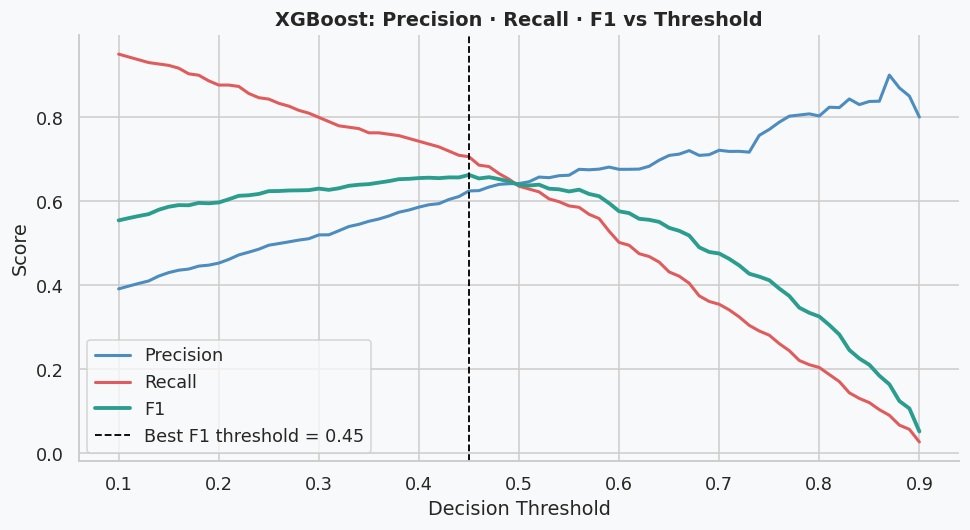

In [13]:
selected_info     = model_registry[preliminary_best_model_name]
selected_val_prob = selected_info["val_prob"]

threshold_df  = threshold_table(y_val, selected_val_prob)
best_f1_row   = threshold_df.loc[threshold_df["F1"].idxmax()]
best_f1_threshold = float(best_f1_row["Threshold"])

print(f"Best validation F1 threshold for {preliminary_best_model_name}: {best_f1_threshold:.2f}")
display(threshold_df.sort_values("F1", ascending=False).head(10))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(threshold_df["Threshold"], threshold_df["Precision"], label="Precision", color=BLUE, lw=2)
ax.plot(threshold_df["Threshold"], threshold_df["Recall"],    label="Recall",    color=RED,  lw=2)
ax.plot(threshold_df["Threshold"], threshold_df["F1"],        label="F1",        color=GREEN, lw=2.5)
ax.axvline(best_f1_threshold, color="black", linestyle="--", lw=1.2,
           label=f"Best F1 threshold = {best_f1_threshold:.2f}")
ax.set_xlabel("Decision Threshold"); ax.set_ylabel("Score")
ax.set_title(f"{preliminary_best_model_name}: Precision · Recall · F1 vs Threshold", fontweight="bold")
ax.legend(); plt.tight_layout(); plt.show()


## 11. Cost-Sensitive Churn Decision

Missing a real churner (FN) is assumed 5× more expensive than a false alarm (FP).
Cost matrix: TP=0, TN=0, FP=1, FN=5.

,Decision Rule,Threshold,FP,FN,Precision,Recall,F1,Total Expected Cost
0,Default 0.50,0.500,106.000,109.000,0.642,0.635,0.639,651.000
1,Best F1 0.45,0.450,127.000,88.000,0.624,0.706,0.662,567.000
2,Best Cost 0.16,0.160,355.000,25.000,0.436,0.916,0.591,480.000


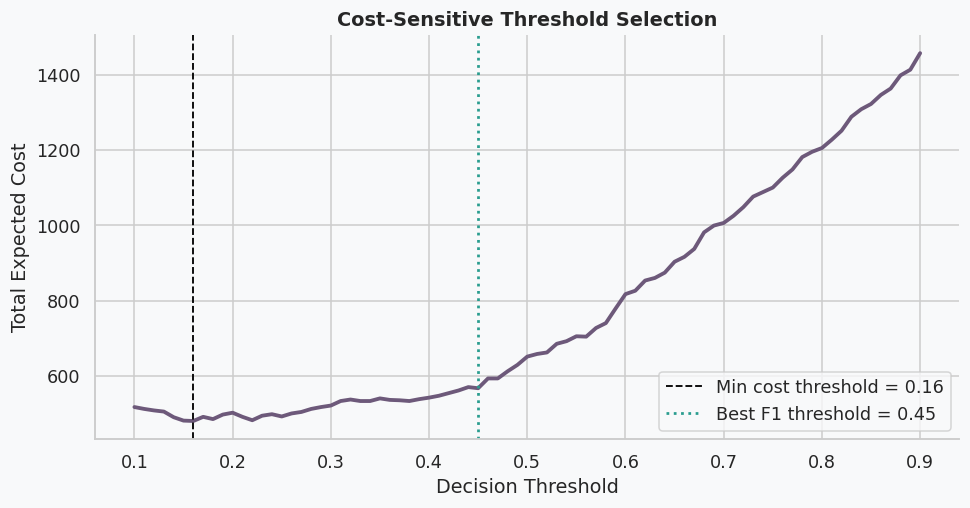

In [14]:
FP_COST, FN_COST = 1, 5

cost_df       = cost_table(y_val, selected_val_prob, fp_cost=FP_COST, fn_cost=FN_COST)
best_cost_row = cost_df.loc[cost_df["Total Expected Cost"].idxmin()]
best_cost_threshold = float(best_cost_row["Threshold"])

def cost_summary_at(label, t):
    row = cost_table(y_val, selected_val_prob, fp_cost=FP_COST, fn_cost=FN_COST,
                     thresholds=[t]).iloc[0].to_dict()
    row["Decision Rule"] = label
    return row

cost_comparison_df = pd.DataFrame([
    cost_summary_at("Default 0.50", 0.50),
    cost_summary_at(f"Best F1 {best_f1_threshold:.2f}", best_f1_threshold),
    cost_summary_at(f"Best Cost {best_cost_threshold:.2f}", best_cost_threshold),
])
display(cost_comparison_df[["Decision Rule","Threshold","FP","FN","Precision","Recall","F1","Total Expected Cost"]])

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(cost_df["Threshold"], cost_df["Total Expected Cost"], color=PURPLE, lw=2.5)
ax.axvline(best_cost_threshold, color="black", linestyle="--", lw=1.2,
           label=f"Min cost threshold = {best_cost_threshold:.2f}")
ax.axvline(best_f1_threshold, color=GREEN, linestyle=":", lw=1.8,
           label=f"Best F1 threshold = {best_f1_threshold:.2f}")
ax.set_xlabel("Decision Threshold"); ax.set_ylabel("Total Expected Cost")
ax.set_title("Cost-Sensitive Threshold Selection", fontweight="bold")
ax.legend(); plt.tight_layout(); plt.show()


## 12. Probability Calibration

Compares Brier score before and after sigmoid/Platt calibration.
Calibration is fitted on train data; assessment is on validation data.
The model is kept calibrated only if Brier score improves.

,Version,Brier Score,ROC AUC
0,Before calibration,0.135,0.852
1,After sigmoid calibration,0.132,0.852


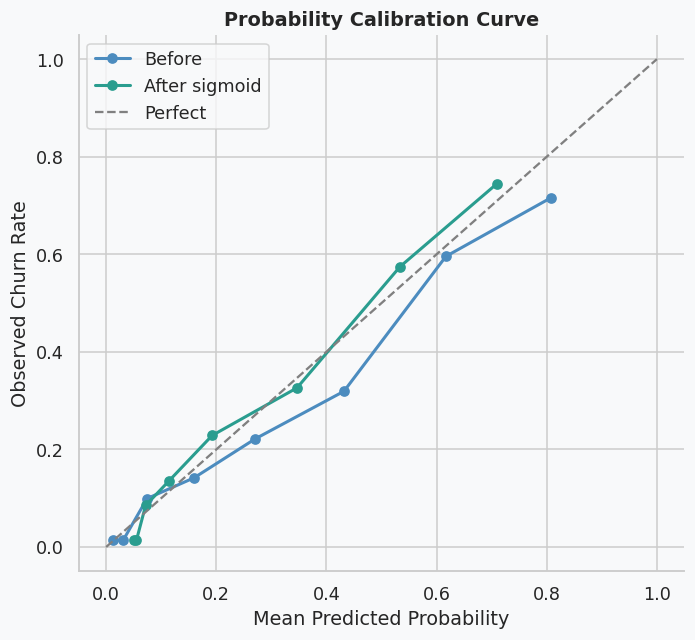

Calibration used: True
Decision probability source: XGBoost + Sigmoid Calibration
Best F1 threshold (decision prob): 0.40
Best cost threshold (decision prob): 0.15


In [15]:
calibration_before = {
    "Version":     "Before calibration",
    "Brier Score": brier_score_loss(y_val, selected_val_prob),
    "ROC AUC":     roc_auc_score(y_val, selected_val_prob),
}

calibration_base = get_candidate_template(preliminary_best_model_name)
calibrated_model = CalibratedClassifierCV(estimator=calibration_base, method="sigmoid", cv=3)

t0 = time.time()
calibrated_model.fit(X_train, y_train)
calibration_train_time = time.time() - t0
calibrated_val_prob = calibrated_model.predict_proba(X_val)[:, 1]

calibration_after = {
    "Version":     "After sigmoid calibration",
    "Brier Score": brier_score_loss(y_val, calibrated_val_prob),
    "ROC AUC":     roc_auc_score(y_val, calibrated_val_prob),
}

USE_CALIBRATED_FINAL = calibration_after["Brier Score"] <= calibration_before["Brier Score"]
decision_model     = calibrated_model if USE_CALIBRATED_FINAL else selected_info["estimator"]
decision_val_prob  = calibrated_val_prob if USE_CALIBRATED_FINAL else selected_val_prob
decision_model_name = (f"{preliminary_best_model_name} + Sigmoid Calibration"
                       if USE_CALIBRATED_FINAL else preliminary_best_model_name)

display(pd.DataFrame([calibration_before, calibration_after]))

fig, ax = plt.subplots(figsize=(6.5, 6))
pt, pp = calibration_curve(y_val, selected_val_prob,    n_bins=8, strategy="quantile")
ptc,ppc= calibration_curve(y_val, calibrated_val_prob, n_bins=8, strategy="quantile")
ax.plot(pp,  pt,  marker="o", color=BLUE,  lw=2, label="Before")
ax.plot(ppc, ptc, marker="o", color=GREEN, lw=2, label="After sigmoid")
ax.plot([0,1],[0,1],"--", color="grey", label="Perfect")
ax.set_xlabel("Mean Predicted Probability"); ax.set_ylabel("Observed Churn Rate")
ax.set_title("Probability Calibration Curve", fontweight="bold")
ax.legend(); plt.tight_layout(); plt.show()

# Recompute thresholds on the chosen probability source
dec_thr_df   = threshold_table(y_val, decision_val_prob)
decision_best_f1_threshold   = float(dec_thr_df.loc[dec_thr_df["F1"].idxmax()]["Threshold"])
dec_cost_df  = cost_table(y_val, decision_val_prob, fp_cost=FP_COST, fn_cost=FN_COST)
decision_best_cost_threshold = float(dec_cost_df.loc[dec_cost_df["Total Expected Cost"].idxmin()]["Threshold"])

print(f"Calibration used: {USE_CALIBRATED_FINAL}")
print(f"Decision probability source: {decision_model_name}")
print(f"Best F1 threshold (decision prob): {decision_best_f1_threshold:.2f}")
print(f"Best cost threshold (decision prob): {decision_best_cost_threshold:.2f}")


## 13. Cross-Validation Stability

5-fold stratified CV on train+val pool. SMOTE stays inside the pipeline and is therefore
applied only to each training fold — no data leakage.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name in ["Logistic Regression", "KNN", "SVM", "Random Forest", "XGBoost"]:
    t0 = time.time()
    scores = cross_validate(
        get_candidate_template(name), X_train_val, y_train_val,
        cv=cv, scoring=["precision", "recall", "f1", "roc_auc"], n_jobs=N_JOBS,
    )
    elapsed = time.time() - t0
    row = {"Model": name, "CV Time (s)": round(elapsed, 1)}
    for m in ["precision", "recall", "f1", "roc_auc"]:
        vals  = scores[f"test_{m}"]
        label = m.upper() if m != "roc_auc" else "ROC AUC"
        row[f"{label} Mean"] = vals.mean()
        row[f"{label} Std"]  = vals.std()
        row[label]           = f"{vals.mean():.3f} ± {vals.std():.3f}"
    cv_rows.append(row)
    print(f"  {name:20s} | F1={row['F1']} | AUC={row['ROC AUC']}")

cv_summary_df = pd.DataFrame(cv_rows)
display(cv_summary_df[["Model","PRECISION","RECALL","F1","ROC AUC","CV Time (s)"]])


  Logistic Regression  | F1=0.627 ± 0.019 | AUC=0.846 ± 0.011
  KNN                  | F1=0.585 ± 0.012 | AUC=0.806 ± 0.013
  SVM                  | F1=0.627 ± 0.020 | AUC=0.842 ± 0.011
  Random Forest        | F1=0.631 ± 0.016 | AUC=0.844 ± 0.008
  XGBoost              | F1=0.634 ± 0.019 | AUC=0.846 ± 0.011


,Model,PRECISION,RECALL,F1,ROC AUC,CV Time (s)
0,Logistic Regression,0.524 ± 0.017,0.781 ± 0.029,0.627 ± 0.019,0.846 ± 0.011,0.400
1,KNN,0.463 ± 0.009,0.797 ± 0.021,0.585 ± 0.012,0.806 ± 0.013,0.600
2,SVM,0.520 ± 0.018,0.790 ± 0.037,0.627 ± 0.020,0.842 ± 0.011,28.500
3,Random Forest,0.568 ± 0.014,0.711 ± 0.027,0.631 ± 0.016,0.844 ± 0.008,4.200
4,XGBoost,0.578 ± 0.020,0.703 ± 0.028,0.634 ± 0.019,0.846 ± 0.011,1.700


## 14. Final Model Selection

Selection criteria (in priority order): validation F1, Recall, ROC AUC, Brier score,
business cost, and CV stability. Accuracy is reported but not the selection criterion.

In [17]:
cv_lookup = cv_summary_df.set_index("Model") if "cv_summary_df" in globals() else pd.DataFrame()
selection_rows = []

for name, info in model_registry.items():
    prob      = info["val_prob"]
    estimator = info["estimator"]
    cal_used  = False

    if name == preliminary_best_model_name and USE_CALIBRATED_FINAL:
        prob      = decision_val_prob
        estimator = calibrated_model
        cal_used  = True

    th_df = threshold_table(y_val, prob)
    th_row= th_df.loc[th_df["F1"].idxmax()]
    co_df = cost_table(y_val, prob, fp_cost=FP_COST, fn_cost=FN_COST)
    co_row= co_df.loc[co_df["Total Expected Cost"].idxmin()]
    m_at_f1 = metric_dict(y_val, prob, threshold=float(th_row["Threshold"]))

    cv_f1_mean = cv_f1_std = cv_rec_mean = cv_auc_mean = np.nan
    if not cv_lookup.empty and name in cv_lookup.index:
        cv_f1_mean = cv_lookup.loc[name].get("F1 Mean", np.nan)
        cv_f1_std  = cv_lookup.loc[name].get("F1 Std",  np.nan)
        cv_rec_mean= cv_lookup.loc[name].get("RECALL Mean", np.nan)
        cv_auc_mean= cv_lookup.loc[name].get("ROC AUC Mean", np.nan)

    selection_rows.append({
        "Model": name, "Learning Type": info["learning_type"],
        "Variant": info["variant"], "Calibration Used": cal_used,
        **m_at_f1,
        "Brier Score":        brier_score_loss(y_val, prob),
        "Best F1 Threshold":  float(th_row["Threshold"]),
        "Best Cost Threshold":float(co_row["Threshold"]),
        "Best Cost":          float(co_row["Total Expected Cost"]),
        "CV F1 Mean": cv_f1_mean, "CV F1 Std": cv_f1_std,
        "CV Recall Mean": cv_rec_mean, "CV ROC AUC Mean": cv_auc_mean,
        "Estimator": estimator, "Decision Prob": prob,
    })

final_selection_table = (
    pd.DataFrame(selection_rows)
    .sort_values(["F1","Recall","ROC AUC","Best Cost","Brier Score"],
                 ascending=[False,False,False,True,True])
    .reset_index(drop=True)
)
display(final_selection_table.drop(columns=["Estimator","Decision Prob"]))

FINAL_MODEL_KEY        = final_selection_table.iloc[0]["Model"]
FINAL_MODEL_NAME       = (f"{FINAL_MODEL_KEY} + Sigmoid Calibration"
                          if bool(final_selection_table.iloc[0]["Calibration Used"])
                          else FINAL_MODEL_KEY)
FINAL_MODEL            = final_selection_table.iloc[0]["Estimator"]
FINAL_F1_THRESHOLD     = float(final_selection_table.iloc[0]["Best F1 Threshold"])
FINAL_DECISION_THRESHOLD = float(final_selection_table.iloc[0]["Best Cost Threshold"])
FINAL_VALIDATION_PROB  = final_selection_table.iloc[0]["Decision Prob"]

print(f"\n>>> Final model: {FINAL_MODEL_NAME}")
print(f"    Best-F1 threshold:       {FINAL_F1_THRESHOLD:.2f}")
print(f"    Business cost threshold: {FINAL_DECISION_THRESHOLD:.2f}")


,Model,Learning Type,Variant,Calibration Used,Accuracy,Precision,Recall,F1,ROC AUC,Brier Score,Best F1 Threshold,Best Cost Threshold,Best Cost,CV F1 Mean,CV F1 Std,CV Recall Mean,CV ROC AUC Mean
0,SVM,Kernel-based,Tuned,False,0.799,0.599,0.726,0.657,0.848,0.159,0.640,0.260,505.000,0.627,0.020,0.790,0.842
1,XGBoost,Gradient boosting,Tuned+ES,True,0.814,0.643,0.669,0.656,0.852,0.132,0.400,0.150,476.000,0.634,0.019,0.703,0.846
2,Random Forest,Bagging ensemble,Tuned,False,0.805,0.622,0.676,0.647,0.847,0.146,0.560,0.270,471.000,0.631,0.016,0.711,0.844
3,Logistic Regression,Linear model,Baseline,False,0.796,0.599,0.696,0.644,0.851,0.157,0.610,0.270,496.000,0.627,0.019,0.781,0.846
4,KNN,Distance-based,Baseline,False,0.742,0.509,0.763,0.610,0.804,0.201,0.590,0.410,535.000,0.585,0.012,0.797,0.806



>>> Final model: SVM
    Best-F1 threshold:       0.64
    Business cost threshold: 0.26


## 15. Final Evaluation

The untouched test set is evaluated here for the first time.
Three thresholds are compared: default 0.50, best-F1, and best-cost.

,Decision Rule,Threshold,Accuracy,Precision,Recall,F1,ROC AUC
0,Default 0.50,0.500,0.753,0.523,0.775,0.625,0.844
1,Best F1 0.64,0.640,0.783,0.573,0.717,0.637,0.844
2,Best Cost 0.26,0.260,0.666,0.438,0.909,0.591,0.844



Classification report — SVM @ threshold 0.26
              precision    recall  f1-score   support

           0       0.95      0.58      0.72      1035
           1       0.44      0.91      0.59       374

    accuracy                           0.67      1409
   macro avg       0.69      0.74      0.65      1409
weighted avg       0.81      0.67      0.68      1409



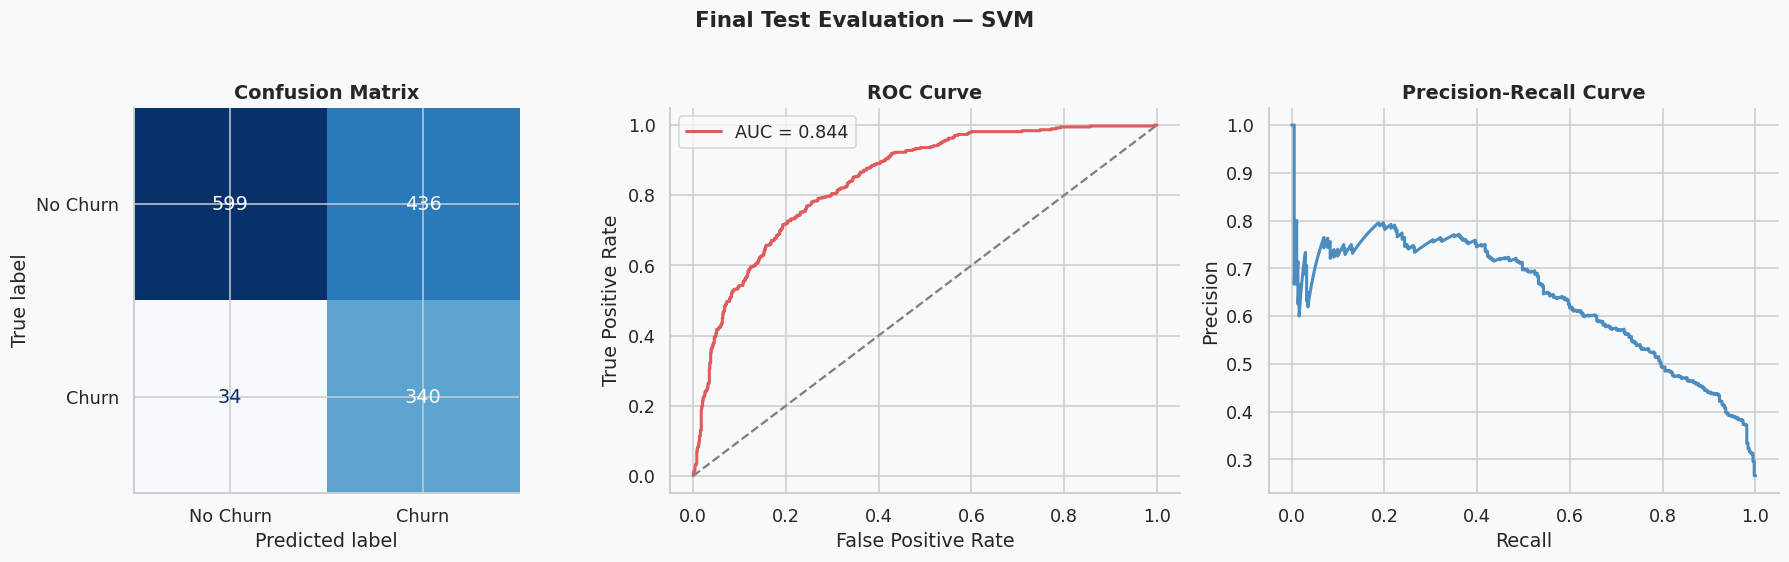

In [18]:
final_test_prob = FINAL_MODEL.predict_proba(X_test)[:, 1]

final_eval_rows = []
for label, t in [
    ("Default 0.50", 0.50),
    (f"Best F1 {FINAL_F1_THRESHOLD:.2f}", FINAL_F1_THRESHOLD),
    (f"Best Cost {FINAL_DECISION_THRESHOLD:.2f}", FINAL_DECISION_THRESHOLD),
]:
    row = {"Decision Rule": label, "Threshold": t}
    row.update(metric_dict(y_test, final_test_prob, threshold=t))
    final_eval_rows.append(row)

final_eval_df = pd.DataFrame(final_eval_rows)
display(final_eval_df)

final_pred    = (final_test_prob >= FINAL_DECISION_THRESHOLD).astype(int)
y_true_final  = y_test

print(f"\nClassification report — {FINAL_MODEL_NAME} @ threshold {FINAL_DECISION_THRESHOLD:.2f}")
print(classification_report(y_true_final, final_pred, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ConfusionMatrixDisplay.from_predictions(
    y_true_final, final_pred, display_labels=["No Churn","Churn"],
    cmap="Blues", ax=axes[0], colorbar=False,
)
axes[0].set_title("Confusion Matrix", fontweight="bold")

fpr, tpr, _ = roc_curve(y_true_final, final_test_prob)
axes[1].plot(fpr, tpr, color=RED, lw=2,
             label=f"AUC = {roc_auc_score(y_true_final, final_test_prob):.3f}")
axes[1].plot([0,1],[0,1],"--", color="grey")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve", fontweight="bold"); axes[1].legend()

prec_vals, rec_vals, _ = precision_recall_curve(y_true_final, final_test_prob)
axes[2].plot(rec_vals, prec_vals, color=BLUE, lw=2)
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-Recall Curve", fontweight="bold")

fig.suptitle(f"Final Test Evaluation — {FINAL_MODEL_NAME}", fontsize=14,
             fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()


## 16. Optional Stacking

Diverse stacking: LR + SVM + RF + XGBoost with a LR meta-model.
Replaces the final model only if it improves validation F1 by ≥ 0.01.

In [19]:
stacking_estimators = [
    ("lr",  LogisticRegression(max_iter=2000, class_weight=cw, random_state=RANDOM_STATE)),
    ("svm", SVC(kernel="rbf", probability=True, class_weight=cw,
                C=best_svm_params.get("C", 1.0),
                gamma=best_svm_params.get("gamma", "scale"),
                random_state=RANDOM_STATE)),
    ("rf",  RandomForestClassifier(
        n_estimators=180,
        max_depth=best_rf_params.get("max_depth", 12),
        min_samples_leaf=best_rf_params.get("min_samples_leaf", 2),
        class_weight=cw, random_state=RANDOM_STATE, n_jobs=N_JOBS)),
    ("xgb", build_xgb_classifier(
        n_estimators=220,
        max_depth=best_xgb_params.get("max_depth", 3),
        learning_rate=best_xgb_params.get("learning_rate", 0.05),
        scale_pos_weight=scale_pos_weight_from_y(y_train, BEST_IMBALANCE_STRATEGY))),
]

stacking_clf  = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    stack_method="predict_proba", cv=3, n_jobs=N_JOBS,
)
stacking_pipe = make_model_pipeline(stacking_clf, balance_strategy=base_balance)

t0 = time.time()
stacking_pipe.fit(X_train, y_train)
stacking_time = time.time() - t0

stacking_val_prob = stacking_pipe.predict_proba(X_val)[:, 1]
stacking_thr_df   = threshold_table(y_val, stacking_val_prob)
stacking_best_thr = float(stacking_thr_df.loc[stacking_thr_df["F1"].idxmax()]["Threshold"])
stacking_f1       = float(stacking_thr_df["F1"].max())

current_f1    = float(final_selection_table.iloc[0]["F1"])
stacking_gain = stacking_f1 - current_f1
STACKING_SELECTED = stacking_gain >= 0.01

display(pd.DataFrame([
    {"Model": FINAL_MODEL_NAME, "Best F1 (val)": current_f1, "Selected": True},
    {"Model": "Diverse Stacking", "Best F1 (val)": stacking_f1, "Selected": STACKING_SELECTED},
]))
print(f"Stacking training time: {stacking_time:.1f}s")
print(f"Stacking F1 gain vs current best: {stacking_gain:+.4f}")
print(f"Stacking adopted as final model: {STACKING_SELECTED}")


,Model,Best F1 (val),Selected
0,SVM,0.657,True
1,Diverse Stacking,0.649,False


Stacking training time: 20.3s
Stacking F1 gain vs current best: -0.0076
Stacking adopted as final model: False


## 17. SHAP Explainability

Global feature importance for the final model using SHAP.
Works correctly regardless of whether the final model is calibrated or not.

PermutationExplainer explainer: 151it [12:00,  4.83s/it]                         


SHAP time: 720.3s  |  Explaining: SVM


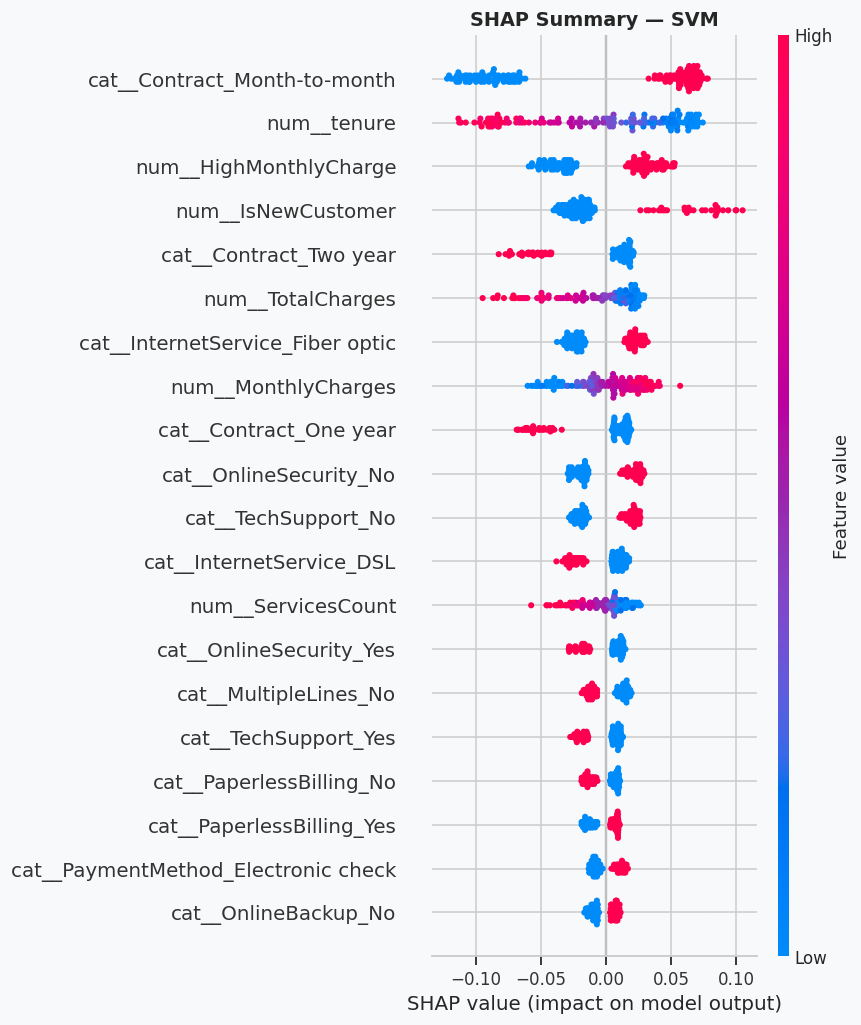

,Feature,Mean |SHAP|
0,cat__Contract_Month-to-month,0.075
1,num__tenure,0.050
2,num__HighMonthlyCharge,0.035
3,num__IsNewCustomer,0.032
4,cat__Contract_Two year,0.025
5,num__TotalCharges,0.024
6,cat__InternetService_Fiber optic,0.023
7,num__MonthlyCharges,0.023
8,cat__Contract_One year,0.022
9,cat__OnlineSecurity_No,0.021


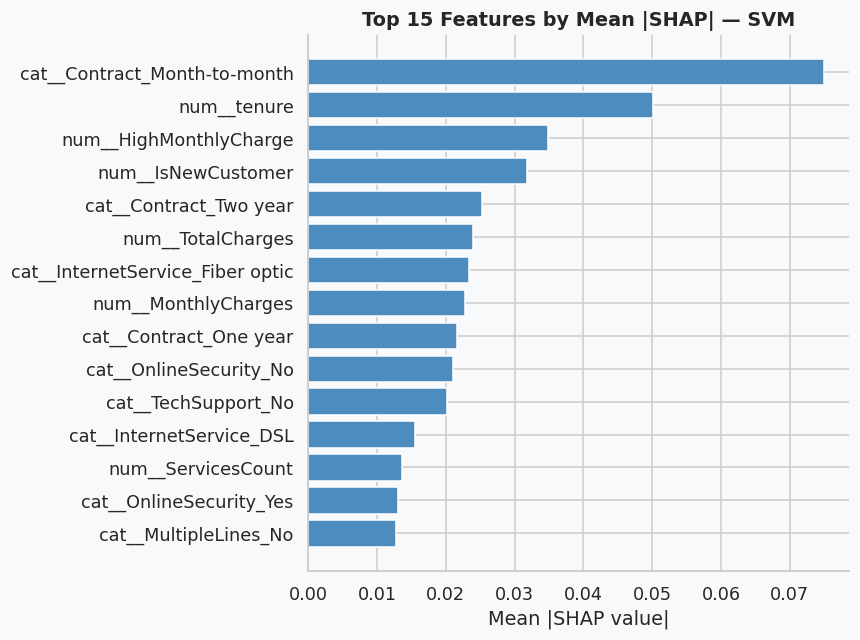

In [20]:
# ── Install SHAP if needed ────────────────────────────────────────────────────
try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

# FIX: handle CalibratedClassifierCV which has no "model" step
# We use the un-calibrated pipeline for SHAP (same preprocessor, raw model)
explain_pipe = model_registry[FINAL_MODEL_KEY]["estimator"]
preprocessor_step = explain_pipe.named_steps["preprocessor"]
model_step        = explain_pipe.named_steps["model"]

X_val_tr = preprocessor_step.transform(X_val)
if hasattr(X_val_tr, "toarray"):
    X_val_tr = X_val_tr.toarray()

feature_names = preprocessor_step.get_feature_names_out()
X_val_tr_df   = pd.DataFrame(X_val_tr, columns=feature_names, index=X_val.index)

n_bg  = min(50,  len(X_val_tr_df))
n_exp = min(150, len(X_val_tr_df))
background_sample = X_val_tr_df.sample(n=n_bg,  random_state=RANDOM_STATE)
explain_sample    = X_val_tr_df.sample(n=n_exp, random_state=RANDOM_STATE)

def predict_proba_positive(X):
    return model_step.predict_proba(X)[:, 1]

t0 = time.time()
explainer   = shap.Explainer(predict_proba_positive, background_sample)
shap_values = explainer(explain_sample)
print(f"SHAP time: {time.time()-t0:.1f}s  |  Explaining: {FINAL_MODEL_NAME}")

shap.summary_plot(shap_values, explain_sample, show=False)
plt.title(f"SHAP Summary — {FINAL_MODEL_NAME}", fontweight="bold")
plt.tight_layout(); plt.show()

mean_shap_df = (
    pd.DataFrame({
        "Feature": feature_names,
        "Mean |SHAP|": np.abs(shap_values.values).mean(axis=0),
    })
    .sort_values("Mean |SHAP|", ascending=False)
    .reset_index(drop=True)
)
display(mean_shap_df.head(15))

fig, ax = plt.subplots(figsize=(8, 6))
top = mean_shap_df.head(15).sort_values("Mean |SHAP|")
ax.barh(top["Feature"], top["Mean |SHAP|"], color=BLUE, edgecolor="white")
ax.set_title(f"Top 15 Features by Mean |SHAP| — {FINAL_MODEL_NAME}", fontweight="bold")
ax.set_xlabel("Mean |SHAP value|")
plt.tight_layout(); plt.show()


## 18. Executive Summary — Consolidated Results

One-slide view: imbalance experiment → model comparison → final test evaluation.

In [22]:
print("=" * 60)
print("  SECTION A — Imbalance Strategy Comparison (All Models)")
print("=" * 60)
display(pivot_f1.round(3))
print(f">>> Best global strategy: {BEST_IMBALANCE_LABEL}")

print("\n" + "=" * 60)
print("  SECTION B — Model Leaderboard (Validation Set)")
print("=" * 60)
display(final_selection_table.drop(columns=["Estimator","Decision Prob"]))
print(f">>> Selected Final Model: {FINAL_MODEL_NAME}")
print(f"    Best-F1 threshold: {FINAL_F1_THRESHOLD:.2f}  |  Business-cost threshold: {FINAL_DECISION_THRESHOLD:.2f}")

print("\n" + "=" * 60)
print("  SECTION C — Final Test-Set Evaluation")
print("=" * 60)
display(final_eval_df)

exec_summary = pd.DataFrame({
    "Metric": [
        "Final Model",
        "Imbalance Strategy",
        "Best-F1 Threshold",
        "Business-Cost Threshold",
        "Test Accuracy  (Business Threshold)",
        "Test Precision (Business Threshold)",
        "Test Recall    (Business Threshold)",
        "Test F1        (Business Threshold)",
        "Test ROC AUC",
    ],
    "Value": [
        FINAL_MODEL_NAME,
        BEST_IMBALANCE_LABEL,
        f"{FINAL_F1_THRESHOLD:.2f}",
        f"{FINAL_DECISION_THRESHOLD:.2f}",
        f"{final_eval_df.iloc[2]['Accuracy']:.3f}",
        f"{final_eval_df.iloc[2]['Precision']:.3f}",
        f"{final_eval_df.iloc[2]['Recall']:.3f}",
        f"{final_eval_df.iloc[2]['F1']:.3f}",
        f"{final_eval_df.iloc[2]['ROC AUC']:.3f}",
    ],
})
print("\n>>> One-Slide Executive Summary")
display(exec_summary)


  SECTION A — Imbalance Strategy Comparison (All Models)


Strategy,Class Weight,No Balancing,SMOTE
Model,,,
KNN,0.581,0.581,0.587
Logistic Regression,0.633,0.612,0.634
Random Forest,0.633,0.573,0.647
SVM,0.631,0.537,0.634
XGBoost,0.633,0.600,0.641


>>> Best global strategy: SMOTE

  SECTION B — Model Leaderboard (Validation Set)


,Model,Learning Type,Variant,Calibration Used,Accuracy,Precision,Recall,F1,ROC AUC,Brier Score,Best F1 Threshold,Best Cost Threshold,Best Cost,CV F1 Mean,CV F1 Std,CV Recall Mean,CV ROC AUC Mean
0,SVM,Kernel-based,Tuned,False,0.799,0.599,0.726,0.657,0.848,0.159,0.640,0.260,505.000,0.627,0.020,0.790,0.842
1,XGBoost,Gradient boosting,Tuned+ES,True,0.814,0.643,0.669,0.656,0.852,0.132,0.400,0.150,476.000,0.634,0.019,0.703,0.846
2,Random Forest,Bagging ensemble,Tuned,False,0.805,0.622,0.676,0.647,0.847,0.146,0.560,0.270,471.000,0.631,0.016,0.711,0.844
3,Logistic Regression,Linear model,Baseline,False,0.796,0.599,0.696,0.644,0.851,0.157,0.610,0.270,496.000,0.627,0.019,0.781,0.846
4,KNN,Distance-based,Baseline,False,0.742,0.509,0.763,0.610,0.804,0.201,0.590,0.410,535.000,0.585,0.012,0.797,0.806


>>> Selected Final Model: SVM
    Best-F1 threshold: 0.64  |  Business-cost threshold: 0.26

  SECTION C — Final Test-Set Evaluation


,Decision Rule,Threshold,Accuracy,Precision,Recall,F1,ROC AUC
0,Default 0.50,0.500,0.753,0.523,0.775,0.625,0.844
1,Best F1 0.64,0.640,0.783,0.573,0.717,0.637,0.844
2,Best Cost 0.26,0.260,0.666,0.438,0.909,0.591,0.844



>>> One-Slide Executive Summary


,Metric,Value
0,Final Model,SVM
1,Imbalance Strategy,SMOTE
2,Best-F1 Threshold,0.64
3,Business-Cost Threshold,0.26
4,Test Accuracy (Business Threshold),0.666
5,Test Precision (Business Threshold),0.438
6,Test Recall (Business Threshold),0.909
7,Test F1 (Business Threshold),0.591
8,Test ROC AUC,0.844


## 19. Production Customer Inference

This section converts the trained churn model into a reusable
single-customer prediction function for production inference.


In [23]:
def predict_customer(customer_df):
    """
    Predict churn probability and business churn decision
    for one or more customer records.

    Parameters
    ----------
    customer_df : pandas.DataFrame
        Customer data using the same feature schema used during training.

    Returns
    -------
    pandas.DataFrame
        Customer-level churn prediction results.
    """

    # Make a copy so the original input is never modified
    X_customer = customer_df.copy()

    # Generate churn probability
    churn_probability = FINAL_MODEL.predict_proba(X_customer)[:, 1]

    # Apply the business decision threshold selected during validation
    churn_prediction = (
        churn_probability >= FINAL_DECISION_THRESHOLD
    ).astype(int)

    # Risk segmentation
    def risk_band(probability):
        if probability < 0.25:
            return "Low Risk"
        elif probability < 0.50:
            return "Medium Risk"
        elif probability < 0.75:
            return "High Risk"
        else:
            return "Critical Risk"

    results = customer_df.copy()

    results["Churn_Probability"] = churn_probability
    results["Churn_Prediction"] = churn_prediction
    results["Churn_Decision"] = np.where(
        churn_prediction == 1,
        "CHURN",
        "NO CHURN"
    )
    results["Risk_Band"] = [
        risk_band(p) for p in churn_probability
    ]

    return results


In [24]:
# Take one customer from the test set
sample_customer = X_test.iloc[[0]].copy()

sample_result = predict_customer(sample_customer)

display(
    sample_result[
        [
            "Churn_Probability",
            "Churn_Prediction",
            "Churn_Decision",
            "Risk_Band"
        ]
    ]
)

,Churn_Probability,Churn_Prediction,Churn_Decision,Risk_Band
437,0.097,0,NO CHURN,Low Risk


## 20. Customer Profile & Business Attributes

This section converts raw customer attributes into business-readable
customer profiles, current service adoption, missing services, and
potential growth opportunities.

In [285]:
def get_customer_profile(customer_df):
    """
    Build a business-readable profile for each customer.
    """

    profile = customer_df.copy()

    service_columns = [
        "PhoneService",
        "MultipleLines",
        "InternetService",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies",
    ]

    # Services the customer currently has
    def get_current_services(row):
        services = []

        if row.get("PhoneService") == "Yes":
            services.append("Phone Service")

        if row.get("MultipleLines") == "Yes":
            services.append("Multiple Lines")

        if row.get("InternetService") in ["DSL", "Fiber optic"]:
            services.append(f"{row['InternetService']} Internet")

        for col, label in {
            "OnlineSecurity": "Online Security",
            "OnlineBackup": "Online Backup",
            "DeviceProtection": "Device Protection",
            "TechSupport": "Tech Support",
            "StreamingTV": "Streaming TV",
            "StreamingMovies": "Streaming Movies",
        }.items():
            if row.get(col) == "Yes":
                services.append(label)

        return services

    # Services the customer does not have
    def get_missing_services(row):
        missing = []

        for col, label in {
            "OnlineSecurity": "Online Security",
            "OnlineBackup": "Online Backup",
            "DeviceProtection": "Device Protection",
            "TechSupport": "Tech Support",
            "StreamingTV": "Streaming TV",
            "StreamingMovies": "Streaming Movies",
        }.items():

            if row.get(col) == "No":
                missing.append(label)

        return missing

    profile["CurrentServices"] = profile.apply(
        get_current_services,
        axis=1
    )

    profile["MissingServices"] = profile.apply(
        get_missing_services,
        axis=1
    )

    # Number of active optional services
    optional_service_columns = [
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies",
    ]

    profile["ActiveOptionalServices"] = (
        profile[optional_service_columns]
        .eq("Yes")
        .sum(axis=1)
    )

    profile["ServiceAdoptionRate"] = (
        profile["ActiveOptionalServices"] /
        len(optional_service_columns)
    )

    return profile

## 21. Customer Financial Value & Churn Exposure

This section estimates the customer's economic value and the financial
exposure associated with churn.

Financial assumptions are configurable and should not be interpreted
as actual company accounting data unless validated with business data.

In [286]:
# ==============================
# Financial Assumptions
# ==============================

FINANCE_CONFIG = {
    "value_horizon_months": 12,
    "margin_rate": 0.40,

    # Estimated campaign costs
    "low_cost_retention": 10.0,
    "standard_retention": 30.0,
    "high_value_retention": 50.0,

    # Expected campaign success assumptions
    "low_cost_retention_success": 0.15,
    "standard_retention_success": 0.25,
    "high_value_retention_success": 0.35,

    # Upsell assumptions
    "upsell_margin_rate": 0.40,
}

In [287]:
def calculate_customer_economics(
    customer_df,
    churn_probability,
    finance_config=FINANCE_CONFIG
):
    """
    Estimate customer value, expected churn loss,
    retention economics and ROI.
    """

    result = customer_df.copy()

    horizon = finance_config["value_horizon_months"]
    margin_rate = finance_config["margin_rate"]

    # -----------------------------
    # 1. Future Revenue
    # -----------------------------
    result["EstimatedFutureRevenue"] = (
        result["MonthlyCharges"] * horizon
    )

    # -----------------------------
    # 2. Future Margin
    # -----------------------------
    result["EstimatedFutureMargin"] = (
        result["EstimatedFutureRevenue"] * margin_rate
    )

    # -----------------------------
    # 3. Expected Churn Loss
    # -----------------------------
    result["ChurnProbability"] = churn_probability

    result["ExpectedChurnLoss"] = (
        result["ChurnProbability"]
        * result["EstimatedFutureMargin"]
    )

    # -----------------------------
    # 4. Existing notebook value
    # -----------------------------
    result["EstimatedCustomerValue"] = np.where(
        result["TotalCharges"] > 0,
        result["MonthlyCharges"] * result["tenure"],
        0
    )

    return result

In [288]:
def assign_value_risk_segment(
    customer_df,
    churn_probability,
    value_cutoff
):
    """
    Assign the customer to the existing
    Value x Churn Risk framework.
    """

    result = customer_df.copy()

    result["ChurnProbability"] = churn_probability

    # Existing notebook logic
    result["EstimatedCustomerValue"] = np.where(
        result["TotalCharges"] > 0,
        result["MonthlyCharges"] * result["tenure"],
        0
    )

    result["ValueBand"] = np.where(
        result["EstimatedCustomerValue"] >= value_cutoff,
        "High Value",
        "Low Value"
    )

    result["RiskBand"] = np.where(
        result["ChurnProbability"] >= 0.60,
        "High Risk",
        "Low Risk"
    )

    conditions = [
        (
            (result["ValueBand"] == "High Value") &
            (result["RiskBand"] == "High Risk")
        ),
        (
            (result["ValueBand"] == "High Value") &
            (result["RiskBand"] == "Low Risk")
        ),
        (
            (result["ValueBand"] == "Low Value") &
            (result["RiskBand"] == "High Risk")
        ),
        (
            (result["ValueBand"] == "Low Value") &
            (result["RiskBand"] == "Low Risk")
        ),
    ]

    choices = [
        "High Value + High Risk",
        "High Value + Low Risk",
        "Low Value + High Risk",
        "Low Value + Low Risk",
    ]

    result["ValueRiskSegment"] = np.select(
        conditions,
        choices,
        default="Unassigned"
    )

    return result

In [289]:
# Compute VALUE_CUTOFF from the test set
_value_risk_df = calculate_customer_economics(
    X_test,
    FINAL_MODEL.predict_proba(X_test)[:, 1]
)
VALUE_CUTOFF = _value_risk_df["EstimatedCustomerValue"].median()

print(f"Production Value Cutoff: ${VALUE_CUTOFF:,.2f}")


Production Value Cutoff: $1,376.85


In [290]:
def recommend_retention_campaign(
    customer,
    churn_probability,
    value_risk_segment,
    expected_churn_loss
):
    """
    Recommend a retention campaign based on
    risk, value, contract, tenure and services.
    """

    recommendations = []

    contract = customer["Contract"]
    monthly = customer["MonthlyCharges"]
    tenure = customer["tenure"]

    # -----------------------------
    # High Value + High Risk
    # -----------------------------
    if value_risk_segment == "High Value + High Risk":

        if contract == "Month-to-month":
            recommendations.append({
                "campaign": "Contract Loyalty Upgrade",
                "type": "Retention",
                "priority": "HIGH",
                "reason": (
                    "High-value customer with high churn risk "
                    "and a month-to-month contract."
                ),
                "estimated_cost":
                    FINANCE_CONFIG["high_value_retention"]
            })

        if customer.get("TechSupport") == "No":
            recommendations.append({
                "campaign": "Premium Tech Support Offer",
                "type": "Retention",
                "priority": "HIGH",
                "reason": (
                    "High-value high-risk customer does not "
                    "currently have Tech Support."
                ),
                "estimated_cost":
                    FINANCE_CONFIG["high_value_retention"]
            })

        if customer.get("OnlineSecurity") == "No":
            recommendations.append({
                "campaign": "Security Protection Bundle",
                "type": "Retention",
                "priority": "HIGH",
                "reason": (
                    "Customer lacks Online Security, creating "
                    "an opportunity to increase perceived value."
                ),
                "estimated_cost":
                    FINANCE_CONFIG["high_value_retention"]
            })

    # -----------------------------
    # Low Value + High Risk
    # -----------------------------
    elif value_risk_segment == "Low Value + High Risk":

        recommendations.append({
            "campaign": "Low-Cost Retention Outreach",
            "type": "Retention",
            "priority": "MEDIUM",
            "reason": (
                "Customer has high churn risk but relatively "
                "low customer value, so a low-cost intervention "
                "is preferred."
            ),
            "estimated_cost":
                FINANCE_CONFIG["low_cost_retention"]
        })

    # -----------------------------
    # High Value + Low Risk
    # -----------------------------
    elif value_risk_segment == "High Value + Low Risk":

        recommendations.append({
            "campaign": "VIP Loyalty & Growth",
            "type": "Growth",
            "priority": "MEDIUM",
            "reason": (
                "High-value customer with low churn risk. "
                "Focus on loyalty and expansion instead of "
                "aggressive retention discounts."
            ),
            "estimated_cost": 0
        })

    # -----------------------------
    # Low Value + Low Risk
    # -----------------------------
    else:

        recommendations.append({
            "campaign": "Standard Customer Growth",
            "type": "Growth",
            "priority": "LOW",
            "reason": (
                "Customer has low churn risk and low estimated "
                "customer value. Use low-cost growth opportunities."
            ),
            "estimated_cost": 0
        })

    return recommendations

In [291]:
def score_campaigns(
    campaigns,
    expected_churn_loss
):
    """
    Rank campaigns using expected economic value.
    """

    scored = []

    for campaign in campaigns:

        cost = campaign["estimated_cost"]

        if campaign["priority"] == "HIGH":
            success_rate = FINANCE_CONFIG[
                "high_value_retention_success"
            ]

        elif campaign["priority"] == "MEDIUM":
            success_rate = FINANCE_CONFIG[
                "standard_retention_success"
            ]

        else:
            success_rate = FINANCE_CONFIG[
                "low_cost_retention_success"
            ]

        expected_value_preserved = (
            expected_churn_loss * success_rate
        )

        expected_net_benefit = (
            expected_value_preserved - cost
        )

        roi = (
            expected_net_benefit / cost
            if cost > 0
            else np.nan
        )

        campaign_result = campaign.copy()

        campaign_result["success_probability"] = success_rate
        campaign_result["expected_value_preserved"] = (
            expected_value_preserved
        )
        campaign_result["expected_net_benefit"] = (
            expected_net_benefit
        )
        campaign_result["expected_roi"] = roi

        scored.append(campaign_result)

    scored = sorted(
        scored,
        key=lambda x: x["expected_net_benefit"],
        reverse=True
    )

    return scored

In [292]:
def recommend_growth_campaign(customer):
    """
    Recommend personalized upsell/cross-sell opportunities.
    """

    opportunities = []

    # Online Security
    if customer.get("OnlineSecurity") == "No":
        opportunities.append({
            "service": "Online Security",
            "campaign": "Security Add-on",
            "reason": (
                "Customer currently does not subscribe "
                "to Online Security."
            ),
            "priority": 1
        })

    # Online Backup
    if customer.get("OnlineBackup") == "No":
        opportunities.append({
            "service": "Online Backup",
            "campaign": "Backup Protection",
            "reason": (
                "Customer currently does not subscribe "
                "to Online Backup."
            ),
            "priority": 2
        })

    # Device Protection
    if customer.get("DeviceProtection") == "No":
        opportunities.append({
            "service": "Device Protection",
            "campaign": "Device Protection Offer",
            "reason": (
                "Customer currently does not subscribe "
                "to Device Protection."
            ),
            "priority": 3
        })

    # Tech Support
    if customer.get("TechSupport") == "No":
        opportunities.append({
            "service": "Tech Support",
            "campaign": "Premium Tech Support",
            "reason": (
                "Customer currently does not subscribe "
                "to Tech Support."
            ),
            "priority": 4
        })

    # Sort
    opportunities = sorted(
        opportunities,
        key=lambda x: x["priority"]
    )

    return opportunities[:3]

## 22. Personalized Churn Explanation

This section generates customer-level churn drivers using SHAP
and translates model-level features into business-readable reasons.

In [293]:
def dense_array(X):
    """Convert sparse matrix to dense numpy array if needed."""
    import scipy.sparse
    if scipy.sparse.issparse(X):
        return X.toarray()
    return np.array(X)


def get_customer_shap_explanation(customer_df, top_n=8):
    """
    Generate local SHAP explanations for one customer.

    Returns:
        DataFrame containing the strongest positive/negative
        churn contributors.
    """

    # SHAP tree explanation is only available for tree models
    if FINAL_MODEL_KEY not in ["Random Forest", "XGBoost"]:
        return pd.DataFrame(
            columns=[
                "Feature",
                "SHAP_Value",
                "Direction"
            ]
        )

    # Get the same pipeline used in the existing notebook
    explain_pipeline = model_registry[FINAL_MODEL_KEY]["estimator"]

    explain_preprocessor = (
        explain_pipeline.named_steps["preprocessor"]
    )

    explain_model = (
        explain_pipeline.named_steps["model"]
    )

    feature_names = (
        explain_preprocessor.get_feature_names_out()
    )

    # Transform customer
    X_customer_matrix = (
        explain_preprocessor.transform(customer_df)
    )

    X_customer_array = dense_array(
        X_customer_matrix
    )

    # SHAP explainer
    explainer = shap.TreeExplainer(
        explain_model
    )

    shap_raw = explainer.shap_values(
        X_customer_array
    )

    # Handle SHAP output formats
    if isinstance(shap_raw, list):

        shap_values = shap_raw[1]

    elif hasattr(shap_raw, "values"):

        values = shap_raw.values

        if values.ndim == 3:
            shap_values = values[:, :, 1]
        else:
            shap_values = values

    else:

        shap_values = shap_raw

    # First / only customer
    contributions = pd.Series(
        shap_values[0],
        index=feature_names
    )

    contributions = (
        contributions
        .sort_values(
            key=lambda x: x.abs(),
            ascending=False
        )
        .head(top_n)
    )

    explanation = pd.DataFrame({
        "Feature": contributions.index,
        "SHAP_Value": contributions.values
    })

    explanation["Direction"] = np.where(
        explanation["SHAP_Value"] > 0,
        "Increases Churn Risk",
        "Decreases Churn Risk"
    )

    return explanation

In [294]:
customer_shap = get_customer_shap_explanation(
    sample_customer,
    top_n=8
)

display(customer_shap)

,Feature,SHAP_Value,Direction


In [295]:
def translate_feature_to_business_reason(
    feature,
    shap_value,
    customer
):
    """
    Translate model feature names into
    business-readable churn reasons.
    """

    direction = (
        "increases"
        if shap_value > 0
        else "decreases"
    )

    # -----------------------------
    # Contract
    # -----------------------------

    if "Contract_Month-to-month" in feature:

        return (
            "The customer is on a month-to-month contract, "
            "which is associated with higher churn risk."
        )

    # -----------------------------
    # Tenure
    # -----------------------------

    if "tenure" in feature:

        if customer["tenure"] <= 12:
            return (
                "The customer has relatively short tenure, "
                "indicating a potentially weaker relationship "
                "with the company."
            )

        elif customer["tenure"] >= 48:
            return (
                "The customer has long tenure, which is "
                "generally associated with stronger retention."
            )

    # -----------------------------
    # Monthly Charges
    # -----------------------------

    if "MonthlyCharges" in feature:

        if shap_value > 0:
            return (
                "The customer's monthly charges are contributing "
                "to elevated churn risk."
            )
        else:
            return (
                "Monthly charges are not currently a major "
                "source of churn pressure."
            )

    # -----------------------------
    # Tech Support
    # -----------------------------

    if "TechSupport_No" in feature:

        return (
            "The customer does not currently have Tech Support, "
            "which may reduce perceived service value."
        )

    # -----------------------------
    # Online Security
    # -----------------------------

    if "OnlineSecurity_No" in feature:

        return (
            "The customer does not currently have Online Security, "
            "creating an opportunity to increase service value."
        )

    # -----------------------------
    # Online Backup
    # -----------------------------

    if "OnlineBackup_No" in feature:

        return (
            "The customer does not currently have Online Backup, "
            "creating a potential service-value gap."
        )

    # -----------------------------
    # Device Protection
    # -----------------------------

    if "DeviceProtection_No" in feature:

        return (
            "The customer does not currently have Device Protection."
        )

    # -----------------------------
    # Internet Service
    # -----------------------------

    if "InternetService_Fiber" in feature:

        return (
            "The customer's internet service type is contributing "
            "to the model's churn assessment."
        )

    # -----------------------------
    # Payment
    # -----------------------------

    if "PaymentMethod_Electronic" in feature:

        return (
            "The customer's payment method is contributing "
            "to the model's churn assessment."
        )

    # -----------------------------
    # Generic fallback
    # -----------------------------

    return (
        f"{feature} is contributing to the model's "
        f"churn assessment."
    )

In [296]:
def explain_customer_churn(
    customer_df,
    top_n=5
):
    """
    Produce business-readable churn explanations.
    """

    shap_df = get_customer_shap_explanation(
        customer_df,
        top_n=top_n
    )

    explanations = []

    customer = customer_df.iloc[0]

    for _, row in shap_df.iterrows():

        reason = translate_feature_to_business_reason(
            row["Feature"],
            row["SHAP_Value"],
            customer
        )

        explanations.append({
            "Feature": row["Feature"],
            "SHAP_Value": row["SHAP_Value"],
            "Direction": row["Direction"],
            "Business_Reason": reason
        })

    if not explanations:
        return pd.DataFrame(columns=["Feature", "SHAP_Value", "Direction", "Business_Reason"])

    return pd.DataFrame(explanations)

In [297]:
customer_explanation = explain_customer_churn(
    sample_customer
)

display(customer_explanation)

,Feature,SHAP_Value,Direction,Business_Reason


## 23. Personalized Retention Campaign Engine

Campaign recommendations are based on:

- Churn risk
- Customer value
- Financial exposure
- Customer services
- SHAP churn drivers
- Contract
- Tenure
- Campaign economics

In [298]:
def generate_retention_campaigns(
    customer_df,
    churn_probability,
    value_risk_segment,
    expected_churn_loss,
    explanation_df
):
    """
    Generate personalized retention campaigns
    based on customer characteristics and churn drivers.
    Falls back to rule-based logic if SHAP explanation is unavailable.
    """

    customer = customer_df.iloc[0]

    campaigns = []

    # Check if SHAP explanation is available
    shap_available = (
        not explanation_df.empty
        and "Feature" in explanation_df.columns
        and len(explanation_df) > 0
    )

    def shap_flags(feature_pattern):
        """Return True if feature pattern is a positive churn driver."""
        if not shap_available:
            return False
        matches = explanation_df[
            explanation_df["Feature"].str.contains(
                feature_pattern, case=False, na=False
            )
            & (explanation_df["SHAP_Value"] > 0)
        ]
        return len(matches) > 0

    # ==================================================
    # 1. CONTRACT CAMPAIGN
    # ==================================================

    contract_month_to_month = (
        customer.get("Contract") == "Month-to-month"
    )

    if shap_flags("Contract_Month-to-month") or contract_month_to_month:

        campaigns.append({
            "Campaign": "Contract Loyalty Upgrade",
            "Type": "Retention",
            "Priority": "HIGH",
            "Offer": (
                "Offer a personalized incentive to move "
                "from month-to-month to a longer-term contract."
            ),
            "Reason": (
                "Month-to-month contract is a significant "
                "positive churn driver for this customer."
            )
        })

    # ==================================================
    # 2. TECH SUPPORT CAMPAIGN
    # ==================================================

    if shap_flags("TechSupport_No") or customer.get("TechSupport") == "No":

        campaigns.append({
            "Campaign": "Tech Support Value Bundle",
            "Type": "Retention",
            "Priority": "HIGH",
            "Offer": (
                "Offer Tech Support as part of a "
                "personalized service-value bundle."
            ),
            "Reason": (
                "The customer lacks Tech Support and "
                "its absence is contributing to churn risk."
            )
        })

    # ==================================================
    # 3. SECURITY CAMPAIGN
    # ==================================================

    if shap_flags("OnlineSecurity_No") or customer.get("OnlineSecurity") == "No":

        campaigns.append({
            "Campaign": "Online Security Protection Bundle",
            "Type": "Retention",
            "Priority": "MEDIUM",
            "Offer": (
                "Offer Online Security as part of "
                "a personalized protection package."
            ),
            "Reason": (
                "The customer does not currently have "
                "Online Security and this feature is "
                "associated with increased churn risk."
            )
        })

    # ==================================================
    # 4. HIGH VALUE CAMPAIGN
    # ==================================================

    if value_risk_segment == "High Value + High Risk":

        campaigns.append({
            "Campaign": "VIP Retention Program",
            "Type": "Retention",
            "Priority": "HIGH",
            "Offer": (
                "Provide a personalized high-value retention "
                "package rather than a generic discount."
            ),
            "Reason": (
                "The customer combines high estimated value "
                "with elevated churn risk."
            )
        })

    # ==================================================
    # 5. LOW VALUE HIGH RISK
    # ==================================================

    if value_risk_segment == "Low Value + High Risk":

        campaigns.append({
            "Campaign": "Low-Cost Digital Retention",
            "Type": "Retention",
            "Priority": "MEDIUM",
            "Offer": (
                "Use a low-cost personalized digital "
                "retention intervention."
            ),
            "Reason": (
                "The customer has elevated churn risk but "
                "lower estimated customer value."
            )
        })

    # Fallback: always have at least one campaign
    if not campaigns:
        campaigns.append({
            "Campaign": "Standard Retention Outreach",
            "Type": "Retention",
            "Priority": "MEDIUM",
            "Offer": "Personalized outreach to understand customer concerns.",
            "Reason": "Customer is predicted to churn."
        })

    return campaigns


In [310]:
def rank_retention_campaigns(
    campaigns,
    expected_churn_loss
):
    """
    Rank campaigns by expected financial benefit.
    """

    ranked = []

    for campaign in campaigns:

        if campaign["Priority"] == "HIGH":

            cost = FINANCE_CONFIG[
                "high_value_retention"
            ]

            success_probability = FINANCE_CONFIG[
                "high_value_retention_success"
            ]

        else:

            cost = FINANCE_CONFIG[
                "standard_retention"
            ]

            success_probability = FINANCE_CONFIG[
                "standard_retention_success"
            ]

        # --------------------------------
        # Expected value preserved
        # --------------------------------

        expected_value_preserved = (
            expected_churn_loss
            * success_probability
        )

        # --------------------------------
        # Net benefit
        # --------------------------------

        expected_net_benefit = (
            expected_value_preserved
            - cost
        )

        # --------------------------------
        # ROI
        # --------------------------------

        roi = (
            expected_net_benefit / cost
            if cost > 0
            else np.nan
        )

        campaign_result = campaign.copy()

        campaign_result["EstimatedCost"] = cost

        campaign_result[
            "ExpectedSuccessProbability"
        ] = success_probability

        campaign_result[
            "ExpectedValuePreserved"
        ] = expected_value_preserved

        campaign_result[
            "ExpectedNetBenefit"
        ] = expected_net_benefit

        campaign_result[
            "ExpectedROI"
        ] = roi

        ranked.append(campaign_result)

    # Highest economic benefit first
    ranked = sorted(
        ranked,
        key=lambda x: x["ExpectedNetBenefit"],
        reverse=True
    )

    return ranked

In [311]:
def select_best_retention_campaign(ranked_campaigns):
    """
    Select the economically justified campaign.
    """

    if not ranked_campaigns:
        return None

    best = ranked_campaigns[0]

    # Do not spend money if expected benefit is negative
    if best["ExpectedNetBenefit"] <= 0:

        return {
            "Decision": "LOW_COST_OR_NO_INTERVENTION",
            "Reason": (
                "Expected financial benefit does not justify "
                "the estimated campaign cost."
            ),
            "Campaign": None
        }

    return {
        "Decision": "INTERVENE",
        "Reason": (
            "Expected financial benefit exceeds "
            "estimated campaign cost."
        ),
        "Campaign": best
    }

In [312]:
def get_personalized_retention_recommendation(
    customer_df,
    churn_probability,
    value_risk_segment,
    expected_churn_loss
):
    """
    Complete personalized retention recommendation.
    """

    # --------------------------------
    # Explain customer
    # --------------------------------

    explanation_df = explain_customer_churn(
        customer_df,
        top_n=8
    )

    # --------------------------------
    # Generate campaigns
    # --------------------------------

    campaigns = generate_retention_campaigns(
        customer_df,
        churn_probability,
        value_risk_segment,
        expected_churn_loss,
        explanation_df
    )

    # --------------------------------
    # Financial ranking
    # --------------------------------

    ranked_campaigns = rank_retention_campaigns(
        campaigns,
        expected_churn_loss
    )

    # --------------------------------
    # Select best
    # --------------------------------

    decision = select_best_retention_campaign(
        ranked_campaigns
    )

    return {
        "explanation": explanation_df,
        "campaigns": ranked_campaigns,
        "decision": decision
    }

In [313]:
# Churn prediction for sample customer
sample_prediction = predict_customer(sample_customer)
sample_probability = float(sample_prediction["Churn_Probability"].iloc[0])

display(sample_prediction[[
    "Churn_Probability", "Churn_Prediction", "Churn_Decision", "Risk_Band"
]])


,Churn_Probability,Churn_Prediction,Churn_Decision,Risk_Band
437,0.097,0,NO CHURN,Low Risk


In [314]:
# Customer profile
sample_profile = get_customer_profile(sample_customer)

display(sample_profile[[
    "tenure", "Contract", "MonthlyCharges", "InternetService",
    "CurrentServices", "MissingServices",
    "ActiveOptionalServices", "ServiceAdoptionRate"
]])


,tenure,Contract,MonthlyCharges,InternetService,CurrentServices,MissingServices,ActiveOptionalServices,ServiceAdoptionRate
437,72,Two year,114.050,Fiber optic,"[Phone Service, Multiple Lines, Fiber optic In...",[],6,1.000


In [315]:
# Financial analysis
sample_financial = calculate_customer_economics(sample_customer, sample_probability)

display(sample_financial[[
    "MonthlyCharges", "tenure", "EstimatedCustomerValue",
    "EstimatedFutureRevenue", "EstimatedFutureMargin",
    "ChurnProbability", "ExpectedChurnLoss"
]])

# Value × Risk segmentation
sample_segment = assign_value_risk_segment(
    sample_customer, sample_probability, VALUE_CUTOFF
)

display(sample_segment[[
    "MonthlyCharges", "tenure", "EstimatedCustomerValue",
    "ValueBand", "RiskBand", "ValueRiskSegment"
]])


,MonthlyCharges,tenure,EstimatedCustomerValue,EstimatedFutureRevenue,EstimatedFutureMargin,ChurnProbability,ExpectedChurnLoss
437,114.050,72,8211.600,1368.600,547.440,0.097,53.230


,MonthlyCharges,tenure,EstimatedCustomerValue,ValueBand,RiskBand,ValueRiskSegment
437,114.050,72,8211.600,High Value,Low Risk,High Value + Low Risk


In [316]:
sample_value_risk_segment = (
    sample_segment["ValueRiskSegment"].iloc[0]
)

sample_expected_loss = float(
    sample_financial["ExpectedChurnLoss"].iloc[0]
)

retention_result = (
    get_personalized_retention_recommendation(
        sample_customer,
        sample_probability,
        sample_value_risk_segment,
        sample_expected_loss
    )
)

In [317]:
print("=" * 60)
print("PERSONALIZED CUSTOMER RETENTION RECOMMENDATION")
print("=" * 60)

print(
    "\nChurn Probability:",
    f"{sample_probability:.2%}"
)

print(
    "Value × Risk Segment:",
    sample_value_risk_segment
)

print(
    "Expected Churn Loss:",
    f"${sample_expected_loss:,.2f}"
)

PERSONALIZED CUSTOMER RETENTION RECOMMENDATION

Churn Probability: 9.72%
Value × Risk Segment: High Value + Low Risk
Expected Churn Loss: $53.23


In [318]:
print("\nTOP CHURN DRIVERS")
print("-" * 40)

display(
    retention_result["explanation"][
        [
            "Feature",
            "SHAP_Value",
            "Direction",
            "Business_Reason"
        ]
    ]
)


TOP CHURN DRIVERS
----------------------------------------


,Feature,SHAP_Value,Direction,Business_Reason


In [319]:
print("\nRECOMMENDED CAMPAIGNS")
print("-" * 40)

for i, campaign in enumerate(
    retention_result["campaigns"],
    start=1
):

    print(f"\n{i}. {campaign['Campaign']}")
    print("Priority:", campaign["Priority"])
    print("Offer:", campaign["Offer"])
    print("Reason:", campaign["Reason"])

    print(
        "Estimated Cost:",
        f"${campaign['EstimatedCost']:,.2f}"
    )

    print(
        "Expected Value Preserved:",
        f"${campaign['ExpectedValuePreserved']:,.2f}"
    )

    print(
        "Expected Net Benefit:",
        f"${campaign['ExpectedNetBenefit']:,.2f}"
    )

    print(
        "Expected ROI:",
        f"{campaign['ExpectedROI']:.2%}"
    )


RECOMMENDED CAMPAIGNS
----------------------------------------

1. Standard Retention Outreach
Priority: MEDIUM
Offer: Personalized outreach to understand customer concerns.
Reason: Customer is predicted to churn.
Estimated Cost: $30.00
Expected Value Preserved: $13.31
Expected Net Benefit: $-16.69
Expected ROI: -55.64%


In [320]:
print("\nFINAL DECISION")
print("-" * 40)

print(
    retention_result["decision"]["Decision"]
)

print(
    retention_result["decision"]["Reason"]
)


FINAL DECISION
----------------------------------------
LOW_COST_OR_NO_INTERVENTION
Expected financial benefit does not justify the estimated campaign cost.


## 24. Personalized Growth & Upsell Engine

For customers predicted as non-churners, identify relevant
cross-sell and upsell opportunities based on current service adoption,
customer value, and churn risk.

In [321]:
UPSELL_CONFIG = {
    "OnlineSecurity": {
        "name": "Online Security",
        "monthly_revenue": 8.0
    },

    "OnlineBackup": {
        "name": "Online Backup",
        "monthly_revenue": 7.0
    },

    "DeviceProtection": {
        "name": "Device Protection",
        "monthly_revenue": 9.0
    },

    "TechSupport": {
        "name": "Tech Support",
        "monthly_revenue": 10.0
    },

    "StreamingTV": {
        "name": "Streaming TV",
        "monthly_revenue": 12.0
    },

    "StreamingMovies": {
        "name": "Streaming Movies",
        "monthly_revenue": 12.0
    }
}

In [322]:
def score_upsell_opportunities(
    customer_df,
    churn_probability
):
    """
    Rank potential upsell/cross-sell services.
    """

    customer = customer_df.iloc[0]

    opportunities = []

    # ----------------------------------
    # Customer value
    # ----------------------------------

    customer_value = (
        customer["MonthlyCharges"]
        * customer["tenure"]
    )

    high_value = (
        customer_value >= VALUE_CUTOFF
    )

    # ----------------------------------
    # Evaluate every missing service
    # ----------------------------------

    for column, config in UPSELL_CONFIG.items():

        # Customer already has service
        if customer[column] != "No":
            continue

        score = 0
        reasons = []

        # ------------------------------
        # Base opportunity
        # ------------------------------

        score += 20

        reasons.append(
            f"Customer does not currently have "
            f"{config['name']}."
        )

        # ------------------------------
        # High value
        # ------------------------------

        if high_value:

            score += 20

            reasons.append(
                "Customer has relatively high estimated value."
            )

        # ------------------------------
        # Stable customer
        # ------------------------------

        if churn_probability < 0.30:

            score += 20

            reasons.append(
                "Customer currently has relatively low churn risk."
            )

        # ------------------------------
        # Longer relationship
        # ------------------------------

        if customer["tenure"] >= 24:

            score += 15

            reasons.append(
                "Customer has an established relationship "
                "with the company."
            )

        # ------------------------------
        # Contract stability
        # ------------------------------

        if customer["Contract"] in [
            "One year",
            "Two year"
        ]:

            score += 15

            reasons.append(
                "Customer has a longer-term contract."
            )

        # ------------------------------
        # Revenue opportunity
        # ------------------------------

        monthly_revenue = config[
            "monthly_revenue"
        ]

        annual_revenue = (
            monthly_revenue * 12
        )

        annual_margin = (
            annual_revenue
            * FINANCE_CONFIG["margin_rate"]
        )

        opportunities.append({

            "Service": config["name"],

            "Feature": column,

            "OpportunityScore": score,

            "Reason": " ".join(reasons),

            "EstimatedMonthlyRevenue":
                monthly_revenue,

            "EstimatedAnnualRevenue":
                annual_revenue,

            "EstimatedAnnualMargin":
                annual_margin
        })

    # ----------------------------------
    # Sort opportunities
    # ----------------------------------

    opportunities = sorted(
        opportunities,
        key=lambda x: (
            x["OpportunityScore"],
            x["EstimatedAnnualMargin"]
        ),
        reverse=True
    )

    return opportunities

In [323]:
# Find a non-churn customer from X_test

test_predictions = predict_customer(X_test)

non_churn_indices = test_predictions[
    test_predictions["Churn_Prediction"] == 0
].index

growth_customer = X_test.loc[
    [non_churn_indices[0]]
].copy()

In [324]:
growth_prediction = predict_customer(
    growth_customer
)

growth_probability = float(
    growth_prediction[
        "Churn_Probability"
    ].iloc[0]
)

print(
    "Churn Probability:",
    f"{growth_probability:.2%}"
)

Churn Probability: 9.72%


In [325]:
growth_opportunities = score_upsell_opportunities(
    growth_customer,
    growth_probability
)

In [326]:
for i, opportunity in enumerate(
    growth_opportunities[:3],
    start=1
):

    print(f"\n{i}. {opportunity['Service']}")

    print(
        "Opportunity Score:",
        opportunity["OpportunityScore"]
    )

    print(
        "Reason:",
        opportunity["Reason"]
    )

    print(
        "Estimated Monthly Revenue:",
        f"${opportunity['EstimatedMonthlyRevenue']:,.2f}"
    )

    print(
        "Estimated Annual Revenue:",
        f"${opportunity['EstimatedAnnualRevenue']:,.2f}"
    )

    print(
        "Estimated Annual Margin:",
        f"${opportunity['EstimatedAnnualMargin']:,.2f}"
    )

In [327]:
def calculate_growth_economics(
    opportunities
):
    """
    Calculate expected incremental revenue
    and margin for growth opportunities.
    """

    results = []

    for opportunity in opportunities:

        # Conservative expected adoption
        expected_adoption = 0.20

        expected_revenue = (
            opportunity[
                "EstimatedAnnualRevenue"
            ]
            * expected_adoption
        )

        expected_margin = (
            opportunity[
                "EstimatedAnnualMargin"
            ]
            * expected_adoption
        )

        result = opportunity.copy()

        result[
            "ExpectedAnnualRevenue"
        ] = expected_revenue

        result[
            "ExpectedAnnualMargin"
        ] = expected_margin

        result[
            "ExpectedIncrementalValue"
        ] = expected_margin

        results.append(result)

    return results

In [328]:
growth_economics = calculate_growth_economics(
    growth_opportunities
)

## 25. Customer Intelligence Decision Engine

This engine combines:

1. Churn prediction
2. Customer profile
3. Customer value
4. Value × risk segmentation
5. Financial exposure
6. SHAP explanations
7. Personalized retention
8. Personalized growth
9. Campaign economics

The output is a complete customer-level business decision.

In [329]:
def analyze_customer(customer_df):
    """
    Complete customer intelligence engine.

    Decision flow:

    Customer
        ↓
    Churn Prediction
        ↓
    Profile
        ↓
    Customer Value
        ↓
    Financial Exposure
        ↓
    Value × Risk
        ↓
    ┌──────────────────┐
    │                  │
    CHURN            NO CHURN
    │                  │
    ↓                  ↓
    RETENTION         UPSELL
    │                  │
    ↓                  ↓
    Campaign          Growth
    Economics         Economics
    """

    customer_df = customer_df.copy()

    # ==================================================
    # 1. CHURN PREDICTION
    # ==================================================

    prediction = predict_customer(
        customer_df
    )

    churn_probability = float(
        prediction[
            "Churn_Probability"
        ].iloc[0]
    )

    churn_prediction = int(
        prediction[
            "Churn_Prediction"
        ].iloc[0]
    )

    decision = (
        "CHURN"
        if churn_prediction == 1
        else "NO CHURN"
    )

    risk_band = prediction[
        "Risk_Band"
    ].iloc[0]

    # ==================================================
    # 2. CUSTOMER PROFILE
    # ==================================================

    profile = get_customer_profile(
        customer_df
    )

    # ==================================================
    # 3. FINANCIAL ANALYSIS
    # ==================================================

    financial = calculate_customer_economics(
        customer_df,
        churn_probability
    )

    estimated_customer_value = float(
        financial[
            "EstimatedCustomerValue"
        ].iloc[0]
    )

    expected_churn_loss = float(
        financial[
            "ExpectedChurnLoss"
        ].iloc[0]
    )

    future_revenue = float(
        financial[
            "EstimatedFutureRevenue"
        ].iloc[0]
    )

    future_margin = float(
        financial[
            "EstimatedFutureMargin"
        ].iloc[0]
    )

    # ==================================================
    # 4. VALUE × RISK SEGMENT
    # ==================================================

    segmentation = assign_value_risk_segment(
        customer_df,
        churn_probability,
        VALUE_CUTOFF
    )

    value_band = segmentation[
        "ValueBand"
    ].iloc[0]

    risk_value_band = segmentation[
        "RiskBand"
    ].iloc[0]

    value_risk_segment = segmentation[
        "ValueRiskSegment"
    ].iloc[0]

    # ==================================================
    # 5. SHAP EXPLANATION
    # ==================================================

    explanation = explain_customer_churn(
        customer_df,
        top_n=8
    )

    # ==================================================
    # 6. DECISION BRANCH
    # ==================================================

    retention_result = None
    growth_result = None

    # ==================================================
    # CHURN CUSTOMER
    # ==================================================

    if churn_prediction == 1:

        retention_result = (
            get_personalized_retention_recommendation(
                customer_df,
                churn_probability,
                value_risk_segment,
                expected_churn_loss
            )
        )

    # ==================================================
    # NON-CHURN CUSTOMER
    # ==================================================

    else:

        growth_opportunities = (
            score_upsell_opportunities(
                customer_df,
                churn_probability
            )
        )

        growth_economics = (
            calculate_growth_economics(
                growth_opportunities
            )
        )

        growth_result = {
            "opportunities":
                growth_economics
        }

    # ==================================================
    # FINAL RESULT
    # ==================================================

    return {

        "prediction": {

            "churn_probability":
                churn_probability,

            "churn_prediction":
                churn_prediction,

            "decision":
                decision,

            "risk_band":
                risk_band
        },

        "customer_profile":
            profile.iloc[0].to_dict(),

        "segmentation": {

            "value_band":
                value_band,

            "risk_band":
                risk_value_band,

            "value_risk_segment":
                value_risk_segment,

            "estimated_customer_value":
                estimated_customer_value
        },

        "financial": {

            "estimated_future_revenue":
                future_revenue,

            "estimated_future_margin":
                future_margin,

            "expected_churn_loss":
                expected_churn_loss
        },

        "explanation":
            explanation.to_dict(
                orient="records"
            ),

        "retention":
            retention_result,

        "growth":
            growth_result
    }

In [330]:
customer_result = analyze_customer(
    sample_customer
)

In [331]:
print("=" * 70)
print("CUSTOMER INTELLIGENCE REPORT")
print("=" * 70)

print(
    "\nChurn Probability:",
    f"{customer_result['prediction']['churn_probability']:.2%}"
)

print(
    "Decision:",
    customer_result[
        "prediction"
    ]["decision"]
)

print(
    "Risk:",
    customer_result[
        "prediction"
    ]["risk_band"]
)

print(
    "Segment:",
    customer_result[
        "segmentation"
    ]["value_risk_segment"]
)

print(
    "Customer Value:",
    f"${customer_result['segmentation']['estimated_customer_value']:,.2f}"
)

print(
    "Expected Churn Loss:",
    f"${customer_result['financial']['expected_churn_loss']:,.2f}"
)

CUSTOMER INTELLIGENCE REPORT

Churn Probability: 9.72%
Decision: NO CHURN
Risk: Low Risk
Segment: High Value + Low Risk
Customer Value: $8,211.60
Expected Churn Loss: $53.23


In [334]:
if customer_result["prediction"]["decision"] == "CHURN":

    print("\n" + "=" * 70)
    print("RETENTION ACTION")
    print("=" * 70)

    retention = customer_result["retention"]

    print(
        "\nDecision:",
        retention["decision"]["Decision"]
    )

    print(
        "Reason:",
        retention["decision"]["Reason"]
    )

    if retention["decision"]["Campaign"]:

        best = retention[
            "decision"
        ]["Campaign"]

        print(
            "\nBEST CAMPAIGN:",
            best["Campaign"]
        )

        print(
            "Offer:",
            best["Offer"]
        )

        print(
            "Reason:",
            best["Reason"]
        )

        print(
            "Expected Value Preserved:",
            f"${best['ExpectedValuePreserved']:,.2f}"
        )

        print(
            "Campaign Cost:",
            f"${best['EstimatedCost']:,.2f}"
        )

        print(
            "Expected Net Benefit:",
            f"${best['ExpectedNetBenefit']:,.2f}"
        )

        print(
            "Expected ROI:",
            f"{best['ExpectedROI']:.2%}"
        )

else:

    print("\n" + "=" * 70)
    print("GROWTH OPPORTUNITIES")
    print("=" * 70)

    opportunities = (
        customer_result[
            "growth"
        ]["opportunities"]
    )

    for i, opportunity in enumerate(
        opportunities[:3],
        start=1
    ):

        print(
            f"\n{i}. {opportunity['Service']}"
        )

        print(
            "Score:",
            opportunity["OpportunityScore"]
        )

        print(
            "Reason:",
            opportunity["Reason"]
        )

        print(
            "Expected Annual Revenue:",
            f"${opportunity['ExpectedAnnualRevenue']:,.2f}"
        )

        print(
            "Expected Annual Margin:",
            f"${opportunity['ExpectedAnnualMargin']:,.2f}"
        )


GROWTH OPPORTUNITIES


## 26. Production API Response Schema

Convert the customer intelligence result into a clean JSON-compatible
structure that can be consumed by an API or an employee-facing chatbot.

In [335]:
def build_api_response(customer_result):
    """
    Convert the internal analysis result into
    a clean production-ready response.
    """

    prediction = customer_result["prediction"]
    segmentation = customer_result["segmentation"]
    financial = customer_result["financial"]

    response = {
        "prediction": {
            "churn_probability": round(
                prediction["churn_probability"], 4
            ),
            "decision": prediction["decision"],
            "risk_band": prediction["risk_band"]
        },

        "segmentation": {
            "value_band": segmentation["value_band"],
            "risk_band": segmentation["risk_band"],
            "value_risk_segment":
                segmentation["value_risk_segment"],
            "estimated_customer_value":
                round(
                    segmentation[
                        "estimated_customer_value"
                    ],
                    2
                )
        },

        "financial": {
            "estimated_future_revenue":
                round(
                    financial[
                        "estimated_future_revenue"
                    ],
                    2
                ),

            "estimated_future_margin":
                round(
                    financial[
                        "estimated_future_margin"
                    ],
                    2
                ),

            "expected_churn_loss":
                round(
                    financial[
                        "expected_churn_loss"
                    ],
                    2
                )
        },

        "churn_drivers": [],

        "recommended_action": None
    }

    # --------------------------------
    # SHAP drivers
    # --------------------------------

    for explanation in customer_result["explanation"]:

        response["churn_drivers"].append({
            "feature":
                explanation["Feature"],

            "impact":
                round(
                    float(
                        explanation["SHAP_Value"]
                    ),
                    4
                ),

            "direction":
                explanation["Direction"],

            "business_reason":
                explanation["Business_Reason"]
        })

    # --------------------------------
    # Retention
    # --------------------------------

    if prediction["decision"] == "CHURN":

        retention = customer_result["retention"]

        best_campaign = (
            retention["decision"]["Campaign"]
        )

        if best_campaign is not None:

            response["recommended_action"] = {

                "action_type":
                    "RETENTION",

                "campaign":
                    best_campaign["Campaign"],

                "offer":
                    best_campaign["Offer"],

                "reason":
                    best_campaign["Reason"],

                "estimated_cost":
                    round(
                        best_campaign[
                            "EstimatedCost"
                        ],
                        2
                    ),

                "expected_value_preserved":
                    round(
                        best_campaign[
                            "ExpectedValuePreserved"
                        ],
                        2
                    ),

                "expected_net_benefit":
                    round(
                        best_campaign[
                            "ExpectedNetBenefit"
                        ],
                        2
                    ),

                "expected_roi":
                    round(
                        best_campaign[
                            "ExpectedROI"
                        ],
                        4
                    )
            }

        else:

            response["recommended_action"] = {
                "action_type":
                    "LOW_COST_RETENTION",

                "reason":
                    retention["decision"]["Reason"]
            }

    # --------------------------------
    # Growth
    # --------------------------------

    else:

        opportunities = (
            customer_result[
                "growth"
            ]["opportunities"]
        )

        response["recommended_action"] = {

            "action_type":
                "GROWTH",

            "opportunities": [

                {
                    "service":
                        opportunity["Service"],

                    "score":
                        opportunity[
                            "OpportunityScore"
                        ],

                    "reason":
                        opportunity["Reason"],

                    "expected_annual_revenue":
                        round(
                            opportunity[
                                "ExpectedAnnualRevenue"
                            ],
                            2
                        ),

                    "expected_annual_margin":
                        round(
                            opportunity[
                                "ExpectedAnnualMargin"
                            ],
                            2
                        )
                }

                for opportunity
                in opportunities[:3]
            ]
        }

    return response

In [336]:
api_result = build_api_response(
    customer_result
)

api_result

{'prediction': {'churn_probability': 0.0972,
  'decision': 'NO CHURN',
  'risk_band': 'Low Risk'},
 'segmentation': {'value_band': 'High Value',
  'risk_band': 'Low Risk',
  'value_risk_segment': 'High Value + Low Risk',
  'estimated_customer_value': 8211.6},
 'financial': {'estimated_future_revenue': 1368.6,
  'estimated_future_margin': 547.44,
  'expected_churn_loss': 53.23},
 'churn_drivers': [],
 'recommended_action': {'action_type': 'GROWTH', 'opportunities': []}}

## 27. Model Saving

Save the full production artifact: model, thresholds, value cutoff, and financial config.

In [337]:
import json
import joblib
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

production_artifact = {
    "model": FINAL_MODEL,
    "model_name": FINAL_MODEL_KEY,
    "decision_threshold": FINAL_DECISION_THRESHOLD,
    "f1_threshold": FINAL_F1_THRESHOLD,
    "value_cutoff": VALUE_CUTOFF,
    "finance_config": FINANCE_CONFIG
}

joblib.dump(
    production_artifact,
    MODEL_DIR / "churn_model.joblib"
)

print("Production artifact saved.")

Production artifact saved.


In [338]:
loaded_artifact = joblib.load(
    "models/churn_model.joblib"
)

print(
    loaded_artifact.keys()
)

dict_keys(['model', 'model_name', 'decision_threshold', 'f1_threshold', 'value_cutoff', 'finance_config'])


In [339]:
print(
    "Model:",
    loaded_artifact["model_name"]
)

print(
    "Decision threshold:",
    loaded_artifact["decision_threshold"]
)

print(
    "Value cutoff:",
    loaded_artifact["value_cutoff"]
)

Model: SVM
Decision threshold: 0.26
Value cutoff: 1376.8500000000001
